# **Project Name**    -  Zomato Restaurant Clustering & Review Sentiment Analysis

##### **Project Type**    - EDA + Classification (NLP Sentiment Analysis) + Unsupervised (Restaurant Clustering)
##### **Contribution**    - Individual
##### **Developer Name -**  Sunil Yadav


# **Project Summary -**

This capstone analyses Zomato restaurants of the Gachibowli area in Hyderabad using two datasets: restaurant metadata (105 restaurants with cost for two, cuisines, collections and timings) and 10,000 customer reviews (100 reviews for each of 100 restaurants, with rating, review text, reviewer popularity, pictures and timestamp). The business goal is threefold: understand what drives customer satisfaction, automatically measure the sentiment of free-text reviews, and group restaurants into meaningful segments so that Zomato can recommend better and restaurant owners can benchmark themselves.

**Data cleaning.** I removed 36 duplicate rows and about 46 rows with missing key fields, converted Rating and Cost to numbers (fixing a stray text value "Like" and thousands separators), split the reviewer Metadata string into Reviews_Count and Followers, parsed the timestamp into Year, Month, Hour and Weekday, and merged both tables. The target Sentiment is Positive for 4-5 star reviews (63%) and Not positive for 1-3 stars (37%).

**Exploratory analysis.** Fifteen charts following the UBM rule (univariate, bivariate, multivariate) plus a word cloud revealed that ratings are polarised (about 38% five-star but 17% one-star). Average restaurant ratings range from 2.40 (Hotel Zara Hi-Fi) to 4.88 (AB's Absolute Barbecues). Costlier restaurants are rated higher (3.78 vs 3.42), reviews with pictures are rated higher (3.86 vs 3.53), Mediterranean and European cuisines are the best rated while Fast Food, Andhra and Biryani are the lowest, and reviewer popularity increases the rating given. Activity peaks between 9 and 11 PM. Numeric features correlate only weakly with rating (maximum 0.14), so the review text is the main signal.

**Hypothesis testing.** Mann-Whitney U tests showed that expensive restaurants (p < 0.001) and reviews with pictures (p = 0.002) have significantly different, higher ratings, while a chi-square test showed no dependence between weekend/weekday and sentiment (p = 0.26).

**Pre-processing.** A complete NLP pipeline was built: contraction expansion, lower-casing, URL, punctuation and number removal, stop-word removal (keeping negations such as "not"), squeezing of elongated words, tokenisation and lemmatisation. Text was vectorised with TF-IDF (unigrams and bigrams, 5,000 features) and reduced to the 3,000 best terms with chi-square. Numeric features were log-transformed, capped with IQR and standardised, the data was split 80:20 with stratification, and class imbalance was handled with balanced class weights. All fitted steps sit inside scikit-learn Pipelines so that no test information leaks into training.

**Modelling.** Logistic Regression, Multinomial Naive Bayes and Random Forest were trained, cross-validated and tuned with GridSearchCV and RandomizedSearchCV. The tuned Logistic Regression was chosen as the final model: accuracy 86.7%, precision 0.897, recall 0.892, F1 0.894 and ROC-AUC 0.942, with the best cross-validated F1 (0.912). Its coefficients show which words drive sentiment: awesome, best, love, amazing and delicious on the positive side and not, worst, bad, disappointing and tasteless on the negative side.

**Clustering.** K-Means on cost, rating, positivity, review length and cuisine variety produced six restaurant segments (silhouette 0.287), from premium high-rated barbecue and buffet places to budget low-rated outlets.

**Deployment and impact.** The final pipeline was saved with joblib and reloaded to predict unseen reviews. Zomato can use it to flag unhappy customers instantly, track restaurant sentiment, and give owners the exact words customers complain about.

# **GitHub Link -**

Paste your GitHub repository link here: https://github.com/sunilyadav160388/Zomato-Project<your-username>/<your-repo>

# **Problem Statement**

**Zomato lists thousands of restaurants and every restaurant collects thousands of free-text reviews. Customers find it hard to choose, and restaurant owners cannot read every review.
This project (1) analyses the restaurant metadata (cost, cuisines, collections, timings) and 10,000 customer reviews, (2) finds what drives good and bad ratings, (3) builds an NLP model that classifies a review as Positive or Negative automatically, and (4) clusters restaurants into groups by cost, cuisine and rating so that Zomato can recommend better and restaurants can benchmark themselves.**

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os, re, glob, warnings, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')            # keep the notebook output clean
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
RANDOM_STATE = 42                            # fixed seed -> reproducible results

### Dataset Loading

In [12]:
# Load Dataset using the correct local paths with spaces
import os
import pandas as pd

meta_path = '/content/Zomato Restaurant names and Metadata.csv'
reviews_path = '/content/Zomato Restaurant reviews.csv'

try:
    meta_raw = pd.read_csv(meta_path)
    reviews_raw = pd.read_csv(reviews_path)
    print('Both files loaded successfully!')
except Exception as e:
    print('Could not load data ->', e)
    raise

Both files loaded successfully!


### Dataset First View

In [13]:
# Dataset First Look
print('--- Restaurant Metadata ---')
display(meta_raw.head())
print('--- Restaurant Reviews ---')
display(reviews_raw.head())

--- Restaurant Metadata ---


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


--- Restaurant Reviews ---


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [16]:
# Dataset Rows & Columns count
print('Metadata rows, columns :', meta_raw.shape)
print('Reviews  rows, columns :', reviews_raw.shape)

Metadata rows, columns : (105, 6)
Reviews  rows, columns : (10000, 7)


### Dataset Information

In [17]:
# Dataset Info
print('--- Metadata ---'); meta_raw.info()
print('\n--- Reviews ---'); reviews_raw.info()

--- Metadata ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB

--- Reviews ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1), object(6)

#### Duplicate Values

In [18]:
# Dataset Duplicate Value Count
print('Duplicate rows in Metadata:', meta_raw.duplicated().sum())
print('Duplicate rows in Reviews :', reviews_raw.duplicated().sum())

Duplicate rows in Metadata: 0
Duplicate rows in Reviews : 36


#### Missing Values/Null Values

In [19]:
# Missing Values/Null Values Count
print('--- Metadata ---'); print(meta_raw.isnull().sum())
print('\n--- Reviews ---'); print(reviews_raw.isnull().sum())

--- Metadata ---
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64

--- Reviews ---
Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64


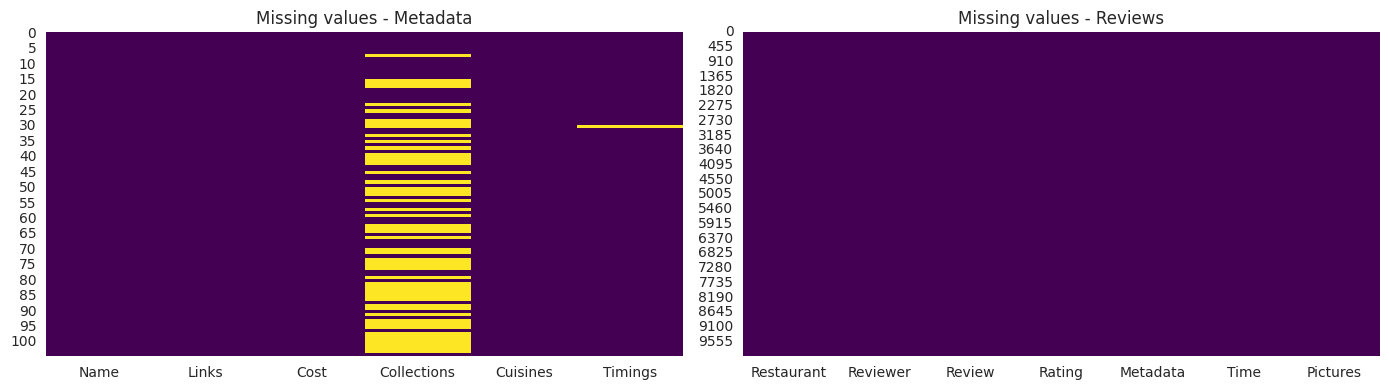

In [20]:
# Visualizing the missing values
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(meta_raw.isnull(), cbar=False, cmap='viridis', ax=ax[0]); ax[0].set_title('Missing values - Metadata')
sns.heatmap(reviews_raw.isnull(), cbar=False, cmap='viridis', ax=ax[1]); ax[1].set_title('Missing values - Reviews')
plt.tight_layout(); plt.show()

### What did you know about your dataset?

* **Metadata** has 105 restaurants (Gachibowli / Hyderabad area) with Name, Links, Cost, Collections, Cuisines and Timings. `Cost` is stored as text with commas (e.g. "1,300"); `Collections` is empty for about half of the restaurants and `Timings` has one missing value.
* **Reviews** has 10,000 rows covering 100 restaurants (exactly 100 reviews each): Restaurant, Reviewer, Review text, Rating, Metadata (reviewer's number of reviews and followers), Time and Pictures.
* There are 36 duplicate review rows and about 38-45 rows with missing Reviewer/Review/Rating/Time.
* `Rating` is stored as text (one wrong value "Like"), `Metadata` hides two numeric features inside a string and `Time` is a string - all need cleaning.
* Five restaurants from the metadata have no reviews, so the two tables are joined on restaurant name.

## ***2. Understanding Your Variables***

In [21]:
# Dataset Columns
print('Metadata columns:', list(meta_raw.columns))
print('Reviews columns :', list(reviews_raw.columns))

Metadata columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Reviews columns : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [22]:
# Dataset Describe
display(meta_raw.describe(include='all').T)
display(reviews_raw.describe(include='all').T)

,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Parijat Ray,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,7/29/2018 20:34,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


### Variables Description

| Column | Table | Description |
|---|---|---|
| Name / Restaurant | both | Restaurant name (join key) |
| Links | Metadata | Zomato page URL of the restaurant |
| Cost | Metadata | Approx. cost for two people (INR) |
| Collections | Metadata | Zomato curated tags such as "Great Buffets", "Top-Rated" |
| Cuisines | Metadata | Comma separated cuisines served |
| Timings | Metadata | Opening hours |
| Reviewer | Reviews | Name of the customer |
| Review | Reviews | Free-text review written by the customer |
| Rating | Reviews | Rating given (1 to 5) - basis of the sentiment label |
| Metadata | Reviews | Reviewer's total reviews and followers |
| Time | Reviews | Date-time of the review |
| Pictures | Reviews | Number of pictures uploaded with the review |

### Check Unique Values for each variable.

In [23]:
# Check Unique Values for each variable.
print('--- Metadata ---'); print(meta_raw.nunique())
print('\n--- Reviews ---'); print(reviews_raw.nunique())

--- Metadata ---
Name           105
Links          105
Cost            29
Collections     42
Cuisines        92
Timings         77
dtype: int64

--- Reviews ---
Restaurant     100
Reviewer      7446
Review        9364
Rating          10
Metadata      2477
Time          9782
Pictures        36
dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [24]:
# Write your code to make your dataset analysis ready.
reviews = reviews_raw.copy()
meta = meta_raw.copy()

# 1. Remove duplicate reviews
reviews = reviews.drop_duplicates()

# 2. Rating is text -> numeric ('Like' and other bad values become NaN) then drop incomplete rows
reviews['Rating'] = pd.to_numeric(reviews['Rating'], errors='coerce')
reviews = reviews.dropna(subset=['Rating', 'Review', 'Reviewer', 'Time']).copy()

# 3. Split the 'Metadata' string ("12 Reviews , 30 Followers") into two numeric features
reviews['Reviews_Count'] = reviews['Metadata'].str.extract(r'(\d+)\s*Review')[0].astype(float).fillna(1)
reviews['Followers'] = reviews['Metadata'].str.extract(r'(\d+)\s*Follower')[0].astype(float).fillna(0)

# 4. Parse time and derive calendar features
reviews['Time'] = pd.to_datetime(reviews['Time'])
reviews['Year'] = reviews['Time'].dt.year
reviews['Month'] = reviews['Time'].dt.month
reviews['Hour'] = reviews['Time'].dt.hour
reviews['Weekday'] = reviews['Time'].dt.day_name()
reviews['Is_Weekend'] = (reviews['Time'].dt.dayofweek >= 5).astype(int)

# 5. Text length features and the sentiment target (4-5 stars = Positive, 1-3 = Negative/Neutral)
reviews['Word_Count'] = reviews['Review'].str.split().str.len()
reviews['Has_Picture'] = (reviews['Pictures'] > 0).astype(int)
reviews['Sentiment'] = (reviews['Rating'] >= 4).astype(int)       # 1 = Positive, 0 = Not positive
reviews = reviews.drop(columns=['Metadata']).reset_index(drop=True)

# 6. Clean the metadata table
meta['Cost'] = meta['Cost'].astype(str).str.replace(',', '').astype(int)
meta['Collections'] = meta['Collections'].fillna('None')
meta['Timings'] = meta['Timings'].fillna('Not Available')
meta['Num_Cuisines'] = meta['Cuisines'].str.split(',').str.len()

# 7. Merge both tables on restaurant name
df = reviews.merge(meta[['Name', 'Cost', 'Cuisines', 'Num_Cuisines', 'Collections']],
                   left_on='Restaurant', right_on='Name', how='left').drop(columns='Name')

# 8. Restaurant level summary (used for charts, clustering)
rest = df.groupby('Restaurant').agg(Avg_Rating=('Rating', 'mean'), Reviews=('Rating', 'size'),
                                    Pos_Share=('Sentiment', 'mean'), Avg_Words=('Word_Count', 'mean'),
                                    Cost=('Cost', 'first'), Num_Cuisines=('Num_Cuisines', 'first')).reset_index()

print('Clean review table :', df.shape, '| restaurants with reviews:', df.Restaurant.nunique())
print('Missing cost after merge:', df['Cost'].isnull().sum())
display(df.head(3))

Clean review table : (9954, 20) | restaurants with reviews: 100
Missing cost after merge: 0


,Restaurant,Reviewer,Review,Rating,Time,Pictures,Reviews_Count,Followers,Year,Month,Hour,Weekday,Is_Weekend,Word_Count,Has_Picture,Sentiment,Cost,Cuisines,Num_Cuisines,Collections
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,2019-05-25 15:54:00,0,1.0,2.0,2019,5,15,Saturday,1,41,0,1,800,"Chinese, Continental, Kebab, European, South I...",6,"Food Hygiene Rated Restaurants in Hyderabad, C..."
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,2019-05-25 14:20:00,0,3.0,2.0,2019,5,14,Saturday,1,27,0,1,800,"Chinese, Continental, Kebab, European, South I...",6,"Food Hygiene Rated Restaurants in Hyderabad, C..."
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,2019-05-24 22:54:00,0,2.0,3.0,2019,5,22,Friday,0,31,0,1,800,"Chinese, Continental, Kebab, European, South I...",6,"Food Hygiene Rated Restaurants in Hyderabad, C..."


### What all manipulations have you done and insights you found?

**Manipulations**
* Removed 36 duplicate reviews and ~46 rows with missing rating/review/reviewer/time (about 0.5% of data lost).
* Converted `Rating` and `Cost` from text to numbers and parsed `Time` into datetime.
* Split the reviewer `Metadata` string into `Reviews_Count` and `Followers`.
* Created new features: Year, Month, Hour, Weekday, Is_Weekend, Word_Count, Has_Picture, Num_Cuisines and the target `Sentiment`.
* Merged review and metadata tables, and built a restaurant-level summary table.

**Insights found**
* About 63% of the reviews are 4-5 stars, so the target is moderately imbalanced (63:37).
* Each of the 100 restaurants has exactly 100 reviews, so every restaurant is represented equally.
* Reviews with no follower information are mostly from first-time reviewers.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### UNIVARIATE ANALYSIS

#### Chart - 1 - Rating Distribution

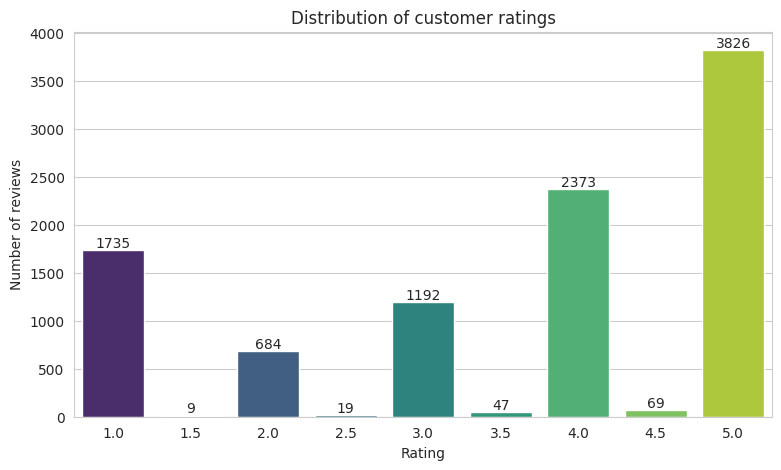

Share of 4-5 star reviews: 63.0% | 1-2 star: 24.4%


In [25]:
# Chart - 1 visualization code
plt.figure(figsize=(9, 5))
ax = sns.countplot(x='Rating', data=df, palette='viridis', order=sorted(df['Rating'].unique()))
for p in ax.patches:                                   # write the count on top of each bar
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.title('Distribution of customer ratings'); plt.xlabel('Rating'); plt.ylabel('Number of reviews')
plt.show()
print(f"Share of 4-5 star reviews: {(df.Rating>=4).mean():.1%} | 1-2 star: {(df.Rating<=2).mean():.1%}")

##### 1. Why did you pick the specific chart?

A count plot is the best way to see how a discrete, ordered variable (1-5 stars) is distributed and to check whether the target is balanced.

##### 2. What is/are the insight(s) found from the chart?

* About 63% of all reviews are 4 or 5 stars and 5 stars alone is the biggest group (~38%).
* 1 star is the second biggest group (~17%), while 2 and 3 stars are small - customers are **polarised**: they either love or hate the experience.
* Half-star ratings (1.5, 2.5, 3.5, 4.5) are very rare.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most customers are satisfied, which supports Zomato's recommendation quality and restaurant reputation.
**Negative:** the large 1-star group (about 1 in 6 reviews) shows inconsistent food or service quality; if these customers do not return, it directly hurts repeat business. Restaurants should read 1-star reviews first and fix the root cause.

#### Chart - 2 - Cost for Two Distribution

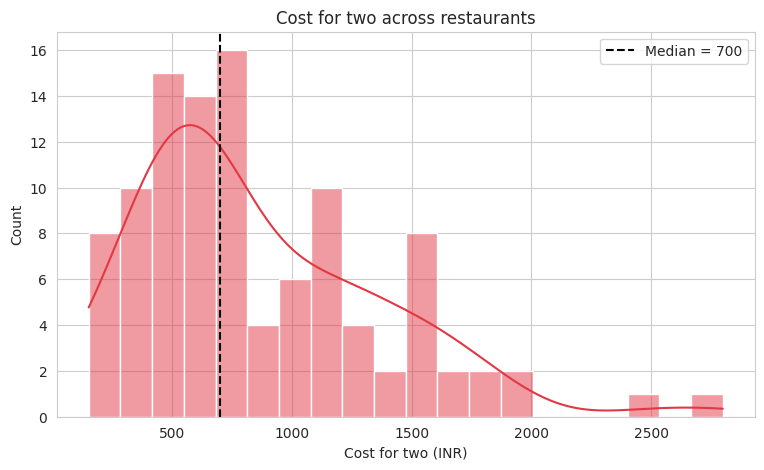

count     105.000000
mean      861.428571
std       510.149730
min       150.000000
25%       500.000000
50%       700.000000
75%      1200.000000
max      2800.000000
Name: Cost, dtype: float64


In [26]:
# Chart - 2 visualization code
plt.figure(figsize=(9, 5))
sns.histplot(meta['Cost'], bins=20, kde=True, color='#e23744')
plt.axvline(meta['Cost'].median(), color='black', ls='--', label=f"Median = {meta['Cost'].median():.0f}")
plt.title('Cost for two across restaurants'); plt.xlabel('Cost for two (INR)'); plt.legend(); plt.show()
print(meta['Cost'].describe())

##### 1. Why did you pick the specific chart?

A histogram with a KDE line shows the shape, spread and skew of a continuous numeric variable like price.

##### 2. What is/are the insight(s) found from the chart?

* Cost is right-skewed: most restaurants charge roughly INR 300-1,300 for two (median about INR 700).
* A thin tail of premium hotel restaurants (Sheraton, Hyatt, Radisson) goes up to INR 2,800.
* The market is dominated by affordable and mid-priced places.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Zomato's biggest audience is price-sensitive, so mid-priced offers, coupons and combos can drive volume.
**Negative:** very few premium restaurants means limited high-margin listings; Zomato could add more fine-dining partners (Gold programme) to grow average order value.



```
# This is formatted as code
```

#### Chart - 3 - Top 10 Cuisines

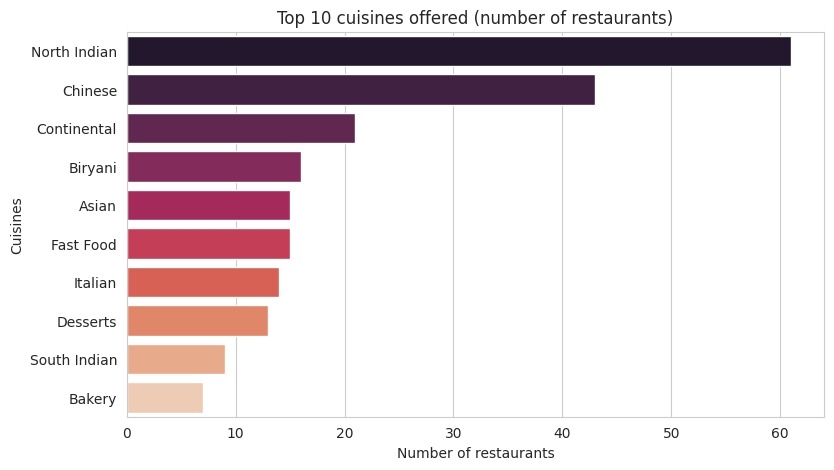

Cuisines
North Indian    61
Chinese         43
Continental     21
Biryani         16
Asian           15
Fast Food       15
Italian         14
Desserts        13
South Indian     9
Bakery           7
Name: count, dtype: int64


In [27]:
# Chart - 3 visualization code
cuisine_counts = meta['Cuisines'].str.split(', ').explode().value_counts().head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index, palette='rocket')
plt.title('Top 10 cuisines offered (number of restaurants)'); plt.xlabel('Number of restaurants')
plt.show()
print(cuisine_counts)

##### 1. Why did you pick the specific chart?

A horizontal bar chart is ideal to rank a categorical variable with long labels (cuisine names).

##### 2. What is/are the insight(s) found from the chart?

* North Indian is served by 61 of 105 restaurants, followed by Chinese (43), Continental (21), Biryani (16), Asian and Fast Food (15 each).
* Local favourites (North Indian, Chinese, Biryani) dominate; niche cuisines such as Mediterranean, Sushi or North Eastern have only a handful of outlets.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing popular cuisines helps Zomato promote what the area wants.
**Negative:** North Indian/Chinese are over-supplied, so competition is intense and margins are squeezed; restaurants in these cuisines need differentiation. Under-served cuisines are an opportunity.

#### Chart - 4 - Reviews Over Time

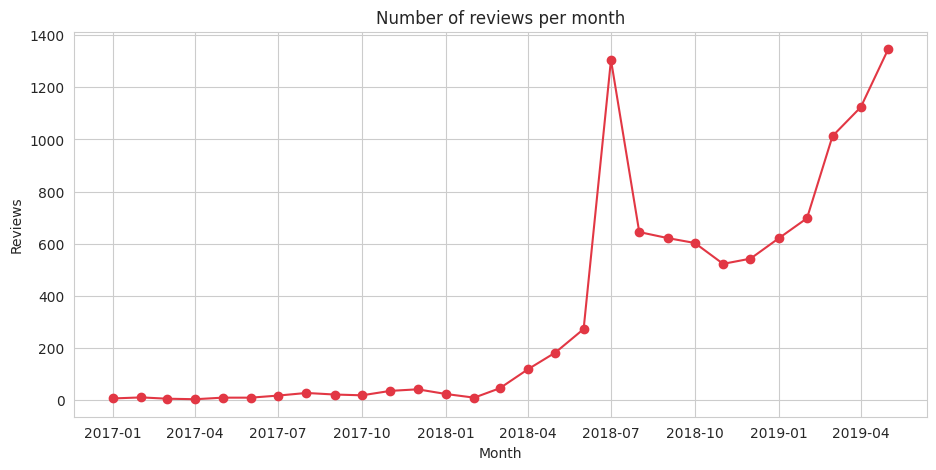

Year
2016      43
2017     213
2018    4896
2019    4802
Name: count, dtype: int64


In [28]:
# Chart - 4 visualization code
monthly = df.groupby(df['Time'].dt.to_period('M')).size()          # works on every pandas version
monthly.index = monthly.index.to_timestamp()
monthly = monthly[monthly.index >= '2017-01-01']
plt.figure(figsize=(11, 5))
plt.plot(monthly.index, monthly.values, marker='o', color='#e23744')
plt.title('Number of reviews per month'); plt.xlabel('Month'); plt.ylabel('Reviews')
plt.show()
print(df['Year'].value_counts().sort_index())

##### 1. Why did you pick the specific chart?

A line chart shows how a quantity changes across time, so it is the natural choice for review volume.

##### 2. What is/are the insight(s) found from the chart?

* Review volume is tiny in 2016-2017 (256 reviews) and jumps to about 4,900 in 2018 and 4,800 in just the first five months of 2019.
* There is a one-month spike in July 2018 (~1,300 reviews), then volume settles at about 500-700 per month; Mar-May 2019 show a steep climb again, with May 2019 the highest (~1,350).
* Caution: because exactly 100 latest reviews were collected per restaurant, the dataset is a "latest reviews" sample - the sharp rise partly reflects sampling and not only real growth.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** strong recent activity means customers are engaged, so feedback is fresh and relevant for current decisions.
**Negative:** no negative growth is visible, but the model should be retrained regularly because language and menu trends change quickly.

#### Chart - 5 - Review Length Distribution

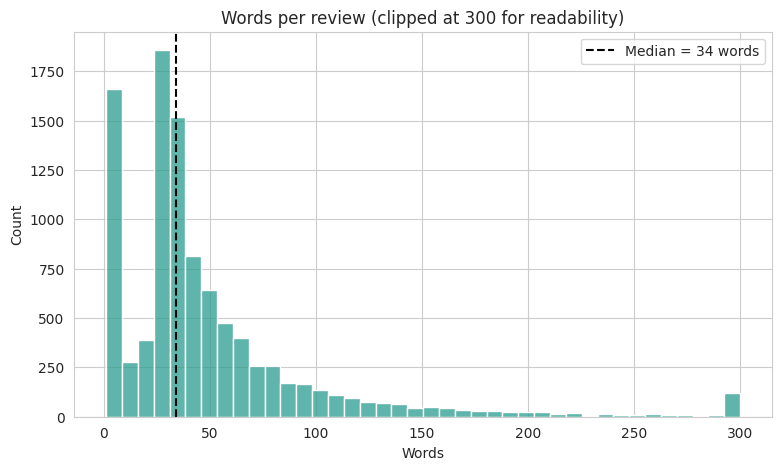

count    9954.000000
mean       50.173297
std        60.786767
min         1.000000
25%        24.000000
50%        34.000000
75%        58.000000
max       964.000000
Name: Word_Count, dtype: float64


In [29]:
# Chart - 5 visualization code
plt.figure(figsize=(9, 5))
sns.histplot(df['Word_Count'].clip(upper=300), bins=40, color='#2a9d8f')
plt.axvline(df['Word_Count'].median(), color='black', ls='--', label=f"Median = {df['Word_Count'].median():.0f} words")
plt.title('Words per review (clipped at 300 for readability)'); plt.xlabel('Words'); plt.legend(); plt.show()
print(df['Word_Count'].describe())

##### 1. Why did you pick the specific chart?

A histogram shows the distribution of a continuous variable and tells us how much text the NLP model will see per review.

##### 2. What is/are the insight(s) found from the chart?

* The median review has only 34 words (mean 50), and 75% are under 58 words.
* There is a long tail of detailed reviews (up to ~960 words).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** short reviews are cheap to process and ideal for TF-IDF models.
**Negative:** very short reviews carry little information, so the model may mis-classify them; Zomato can prompt users with guided questions (food, service, ambience) to get richer feedback.

### BIVARIATE ANALYSIS

#### Chart - 6 - Best and Worst Rated Restaurants

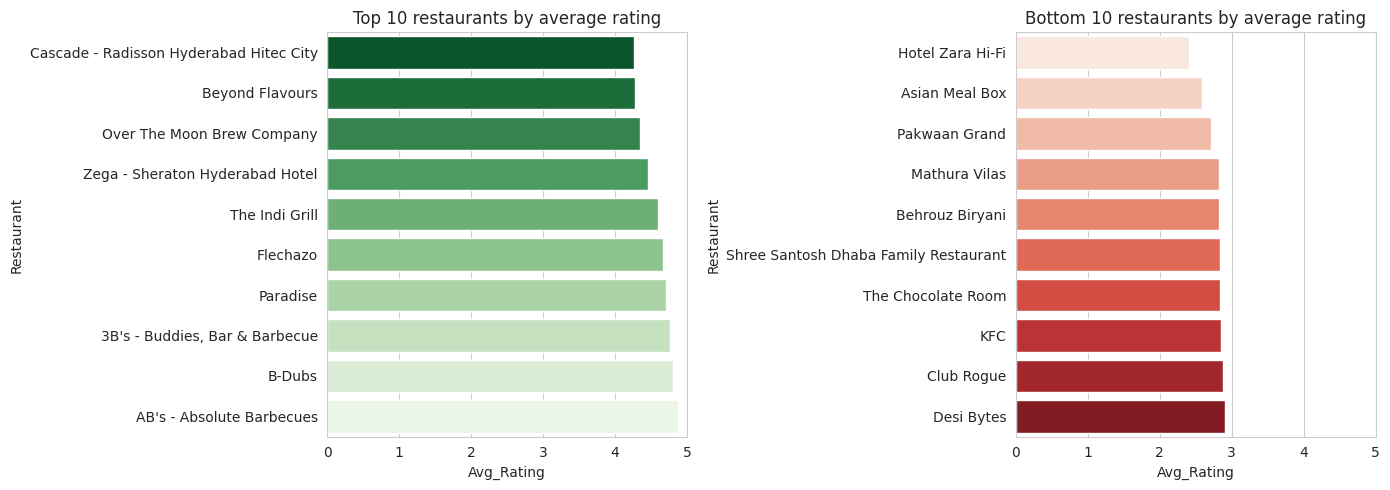

,Restaurant,Avg_Rating,Cost
35,Flechazo,4.66,1300
67,Paradise,4.70,800
2,"3B's - Buddies, Bar & Barbecue",4.76,1100
11,B-Dubs,4.81,1600
3,AB's - Absolute Barbecues,4.88,1500


,Restaurant,Avg_Rating,Cost
41,Hotel Zara Hi-Fi,2.400,400
10,Asian Meal Box,2.580,200
66,Pakwaan Grand,2.710,400
57,Mathura Vilas,2.820,500
14,Behrouz Biryani,2.825,600


In [30]:
# Chart - 6 visualization code
ordered = rest.sort_values('Avg_Rating')
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x='Avg_Rating', y='Restaurant', data=ordered.tail(10), palette='Greens_r', ax=ax[0]); ax[0].set_title('Top 10 restaurants by average rating')
sns.barplot(x='Avg_Rating', y='Restaurant', data=ordered.head(10), palette='Reds', ax=ax[1]); ax[1].set_title('Bottom 10 restaurants by average rating')
for a in ax: a.set_xlim(0, 5)
plt.tight_layout(); plt.show()
display(ordered.tail(5)[['Restaurant', 'Avg_Rating', 'Cost']]); display(ordered.head(5)[['Restaurant', 'Avg_Rating', 'Cost']])

##### 1. Why did you pick the specific chart?

*A* bar chart for a categorical-vs-numerical comparison; showing top and bottom 10 side by side makes the spread between best and worst obvious.

##### 2. What is/are the insight(s) found from the chart?

* Best: AB's - Absolute Barbecues (4.88), B-Dubs (4.81), 3B's (4.76), Paradise (4.70) and Flechazo (4.66) - mostly barbecue/buffet and sit-down experiences.
* Worst: Hotel Zara Hi-Fi (2.40), Asian Meal Box (2.58), Pakwaan Grand (2.71), Mathura Vilas (2.82) and Behrouz Biryani (2.83).
* The gap between best and worst is huge (2.4 vs 4.9).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Zomato can feature the top restaurants and use them as benchmarks.
**Negative:** the bottom restaurants are a reputation risk for the platform - low ratings reduce orders and can lead to customer churn. Zomato should give them quality-improvement feedback or reduce their visibility until quality improves.

#### Chart - 7 - Cost vs Average Rating

> Add blockquote



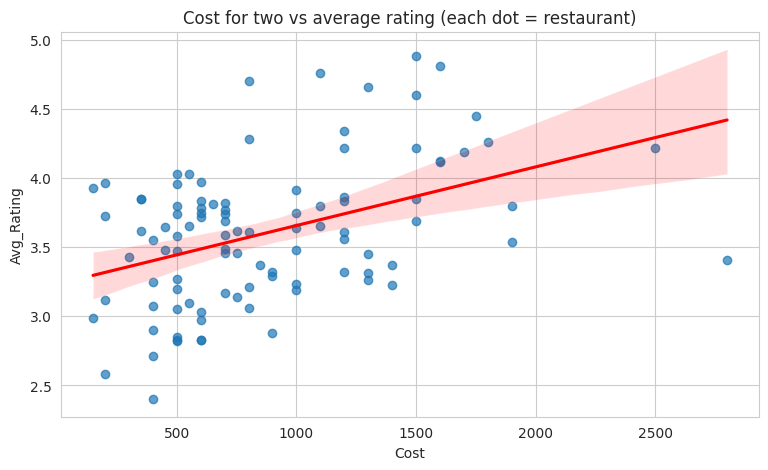

Correlation (restaurant level): 0.42


In [31]:
# Chart - 7 visualization code
plt.figure(figsize=(9, 5))
sns.regplot(x='Cost', y='Avg_Rating', data=rest, scatter_kws={'alpha': .7}, line_kws={'color': 'red'})
plt.title('Cost for two vs average rating (each dot = restaurant)'); plt.show()
print('Correlation (restaurant level):', rest[['Cost', 'Avg_Rating']].corr().iloc[0, 1].round(2))

##### 1. Why did you pick the specific chart?

A scatter plot with a regression line is the standard chart for a numerical-vs-numerical relationship.

> Add blockquote



##### 2. What is/are the insight(s) found from the chart?

* There is a clear positive trend: costlier restaurants tend to have higher average ratings.
* Restaurants above the median cost average ~3.78 stars vs ~3.42 for cheaper ones.
* Many cheap restaurants still score very high, so price is not the only driver.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** customers accept paying more when quality is delivered - premium restaurants are safe to promote.
**Negative:** cheap restaurants with poor ratings (below 3) are a risk; discounts will not fix quality problems and may only increase negative reviews.

#### Chart - 8 - Review Length by Rating

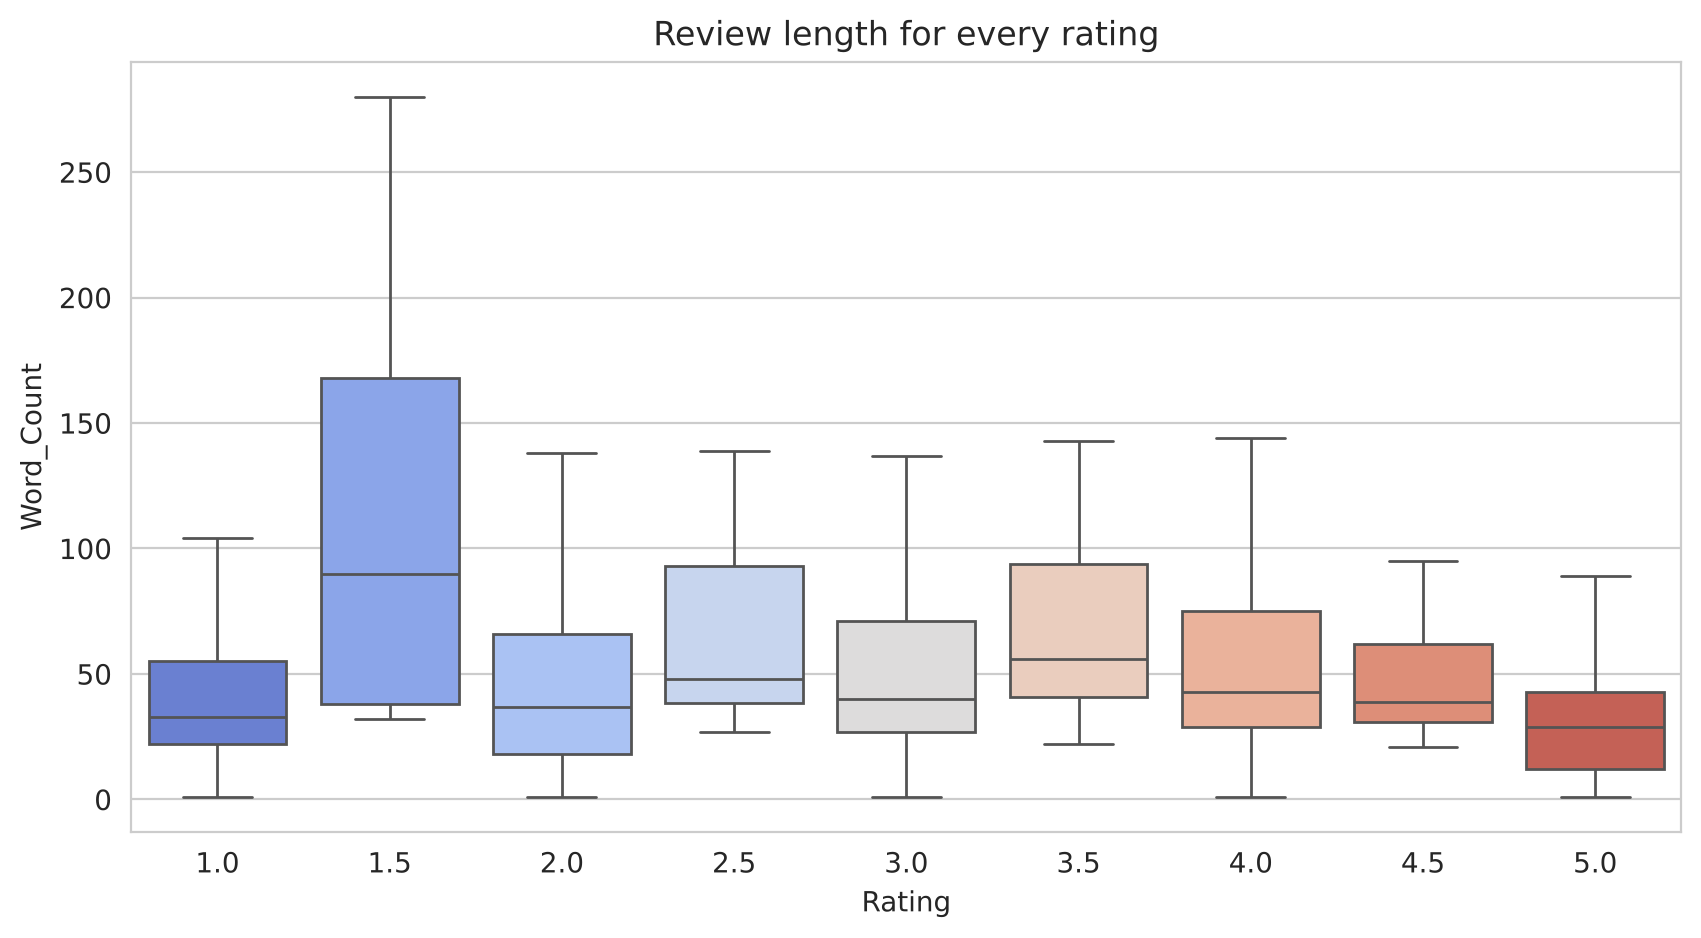

Rating
1.0    33.0
1.5    90.0
2.0    37.0
2.5    48.0
3.0    40.0
3.5    56.0
4.0    43.0
4.5    39.0
5.0    29.0
Name: Word_Count, dtype: float64


In [ ]:
# Chart - 8 visualization code
plt.figure(figsize=(10, 5))
sns.boxplot(x='Rating', y='Word_Count', data=df, showfliers=False, palette='coolwarm')
plt.title('Review length for every rating'); plt.show()
print(df.groupby('Rating')['Word_Count'].median())

##### 1. Why did you pick the specific chart?

A box plot compares the distribution (median, spread, outliers) of a numeric variable across categories.

##### 2. What is/are the insight(s) found from the chart?

* 5-star reviews are the shortest (median 29 words); middle ratings are the longest (3 stars = 40, 4 stars = 43 words) - people who are mixed write more to explain the pros and cons, while delighted customers write a quick "loved it".
* The overall correlation between length and rating is almost zero (-0.04), so review length alone cannot predict the rating - the actual words are what matter.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms that text content (not length) must be analysed, justifying our NLP model.
**Negative:** the longer 1-4 star reviews contain the most useful complaints and suggestions; ignoring them wastes information that restaurants could act upon.

#### Chart - 9 - Pictures vs Rating

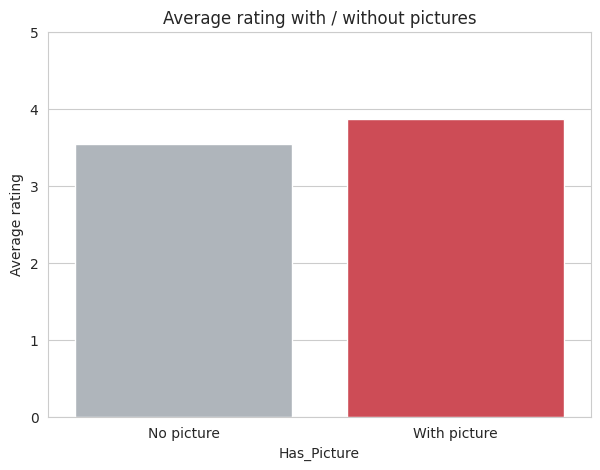

                  mean  count
Has_Picture                  
No picture    3.534814   7971
With picture  3.863338   1983


In [32]:
# Chart - 9 visualization code
pic = df.groupby('Has_Picture')['Rating'].agg(['mean', 'count']).rename(index={0: 'No picture', 1: 'With picture'})
plt.figure(figsize=(7, 5))
sns.barplot(x=pic.index, y=pic['mean'], palette=['#adb5bd', '#e23744'])
plt.ylim(0, 5); plt.title('Average rating with / without pictures'); plt.ylabel('Average rating'); plt.show()
print(pic)

##### 1. Why did you pick the specific chart?

A simple bar chart of group means is the clearest way to compare a numeric

outcome between two groups.

##### 2. What is/are the insight(s) found from the chart?

* Reviews with pictures average about 3.86 stars versus 3.53 without pictures.
* Only about 20% of reviews contain pictures.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** happy customers share photos, which is free marketing - Zomato can reward photo reviews.
**Negative:** photo-less reviews are more negative on average; restaurants relying only on text reviews may appear less attractive than they really are.

#### Chart - 10 - Reviews by Hour of the Day




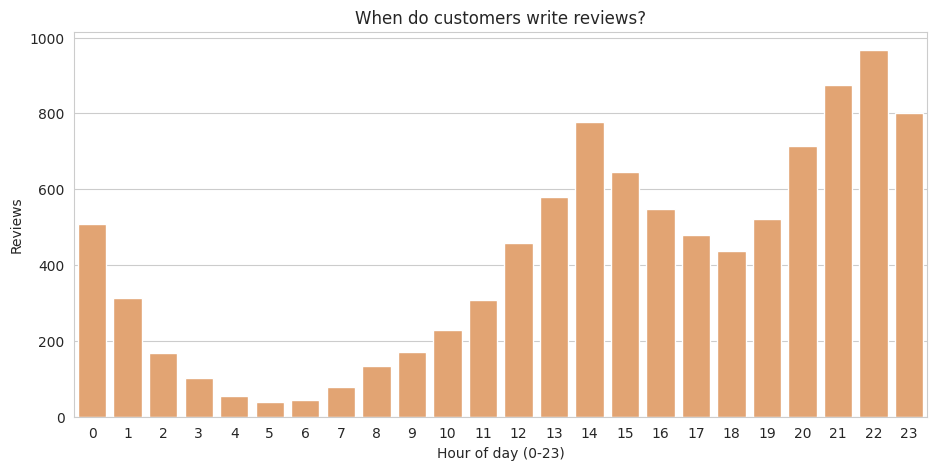

Hour
22    967
21    875
23    802
14    776
20    714
Name: count, dtype: int64


In [33]:
# Chart - 10 visualization code
hourly = df['Hour'].value_counts().sort_index()
plt.figure(figsize=(11, 5))
sns.barplot(x=hourly.index, y=hourly.values, color='#f4a261')
plt.title('When do customers write reviews?'); plt.xlabel('Hour of day (0-23)'); plt.ylabel('Reviews'); plt.show()
print(hourly.sort_values(ascending=False).head(5))

##### 1. Why did you pick the specific chart?

A bar chart over 24 hours shows the daily rhythm of customer activity clearly.

##### 2. What is/are the insight(s) found from the chart?

* Two peaks: lunch time (about 1-3 PM) and a big late-evening peak 9-11 PM (highest at 10 PM with ~970 reviews).
* Very few reviews between 4 AM and 7 AM.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Zomato can send review-reminder notifications around 9-10 PM to collect more feedback.
**Negative:** early-morning inactivity means breakfast restaurants receive little feedback and are harder to evaluate.

#### Chart - 11 - Average Rating by Weekday





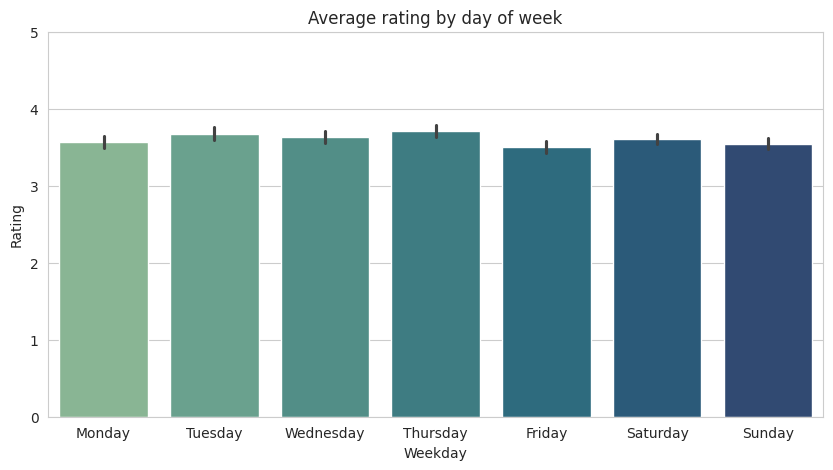

Weekday
Monday       3.56
Tuesday      3.68
Wednesday    3.63
Thursday     3.71
Friday       3.50
Saturday     3.61
Sunday       3.54
Name: Rating, dtype: float64


In [34]:
# Chart - 11 visualization code
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(10, 5))
sns.barplot(x='Weekday', y='Rating', data=df, order=order, palette='crest')
plt.ylim(0, 5); plt.title('Average rating by day of week'); plt.show()
print(df.groupby('Weekday')['Rating'].mean().reindex(order).round(2))

##### 1. Why did you pick the specific chart?

A bar chart with ordered categories shows whether a weekly pattern exists.

##### 2. What is/are the insight(s) found from the chart?

* Ratings are highest on Thursday (3.71) and Tuesday (3.68) and lowest on Friday (3.50) and Sunday (3.54).
* The overall difference is small (about 0.2 stars).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** quieter weekdays give better experiences.
**Negative:** Friday/weekend ratings are lower, probably due to crowding and slower service - restaurants should add staff and manage waiting times on busy days.

#### Chart - 12 - Average Rating by Cuisine

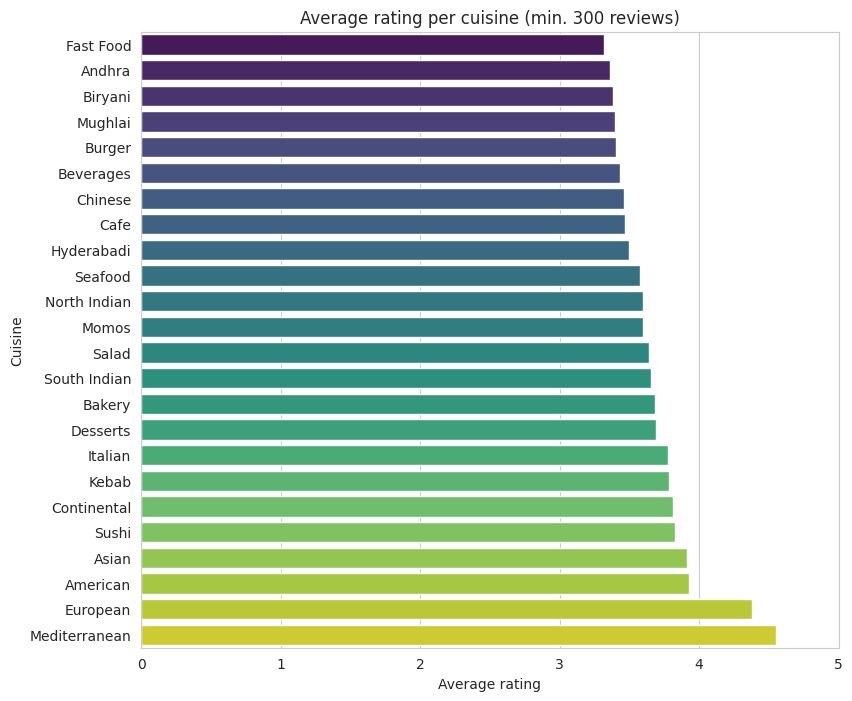

               mean  count
Cuisine                   
Sushi          3.83    400
Asian          3.92   1400
American       3.93    577
European       4.38    400
Mediterranean  4.55    500
           mean  count
Cuisine               
Fast Food  3.32   1276
Andhra     3.36    600
Biryani    3.38   1498
Mughlai    3.40    600
Burger     3.40    477


In [35]:
# Chart - 12 visualization code
cz = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine').groupby('Cuisine')['Rating'].agg(['mean', 'count'])
cz = cz[cz['count'] >= 300].sort_values('mean')          # keep cuisines with enough reviews
plt.figure(figsize=(9, 8))
sns.barplot(x=cz['mean'], y=cz.index, palette='viridis')
plt.xlim(0, 5); plt.title('Average rating per cuisine (min. 300 reviews)'); plt.xlabel('Average rating'); plt.show()
print(cz.round(2).tail(5)); print(cz.round(2).head(5))

##### 1. Why did you pick the specific chart?

A sorted horizontal bar chart is the best way to compare many categories on one metric.

##### 2. What is/are the insight(s) found from the chart?

* Mediterranean (4.55), European (4.38), American (3.93) and Asian (3.92) are the best rated cuisines.
* Fast Food (3.32), Andhra (3.36), Biryani (3.38) and Mughlai (3.40) are the lowest.
* The most common cuisines (North Indian 3.60, Chinese 3.46) are only average.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** specialised/premium cuisines delight customers - good candidates for promotion.
**Negative:** Biryani and Fast Food have high demand but low satisfaction; this suggests quality or delivery problems (cold or late food) that can lead to churn, and need focused improvement.

#### Chart - 13 - Reviewer Experience vs Rating

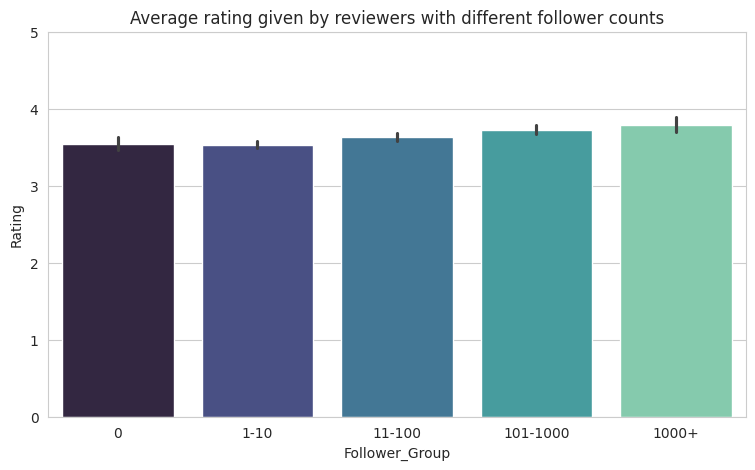

                mean  count
Follower_Group             
0               3.55   1574
1-10            3.53   3919
11-100          3.63   2469
101-1000        3.73   1557
1000+           3.79    435


In [36]:
# Chart - 13 visualization code
df['Follower_Group'] = pd.cut(df['Followers'], [-1, 0, 10, 100, 1000, 1e7], labels=['0', '1-10', '11-100', '101-1000', '1000+'])
plt.figure(figsize=(9, 5))
sns.barplot(x='Follower_Group', y='Rating', data=df, palette='mako')
plt.ylim(0, 5); plt.title('Average rating given by reviewers with different follower counts'); plt.show()
print(df.groupby('Follower_Group')['Rating'].agg(['mean', 'count']).round(2))

##### 1. Why did you pick the specific chart?

Binning a skewed numeric variable (followers) and plotting group means reveals the trend that a raw scatter plot would hide.

##### 2. What is/are the insight(s) found from the chart?

* Ratings rise with reviewer popularity: 3.53-3.55 for new reviewers up to 3.78 for reviewers with 1000+ followers.
* Most reviewers (about 80%) have fewer than 100 followers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** influential reviewers are more positive, so inviting them to try restaurants (food-blogger programmes) can create good word-of-mouth.
**Negative:** new/low-follower reviewers are slightly harsher, which may reflect real service problems for ordinary customers - influencer reviews alone can give a rosier picture than reality.

### MULTIVARIATE ANALYSIS

#### Chart - 14 - Correlation Heatmap

---



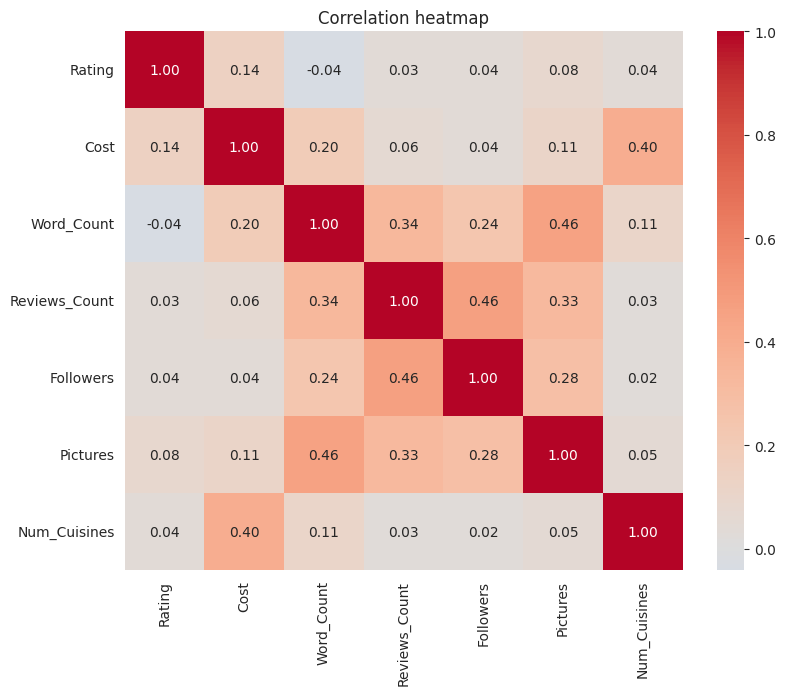

In [37]:
# Correlation Heatmap visualization code
num_cols = ['Rating', 'Cost', 'Word_Count', 'Reviews_Count', 'Followers', 'Pictures', 'Num_Cuisines']
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap'); plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows the strength and direction of the linear relationship between all numeric variables in one picture and helps detect multicollinearity.

##### 2. What is/are the insight(s) found from the chart?

* Rating has only weak correlation with every numeric variable (Cost +0.14, Pictures +0.08), so numeric metadata alone cannot predict sentiment - text is required.
* Strongest relations: Word_Count-Pictures (0.46), Reviews_Count-Followers (0.46) and Word_Count-Reviews_Count (0.32): active reviewers write longer reviews and upload photos.
* No pair is above 0.5, so multicollinearity is not a problem.

#### Chart - 15 - Pair Plot

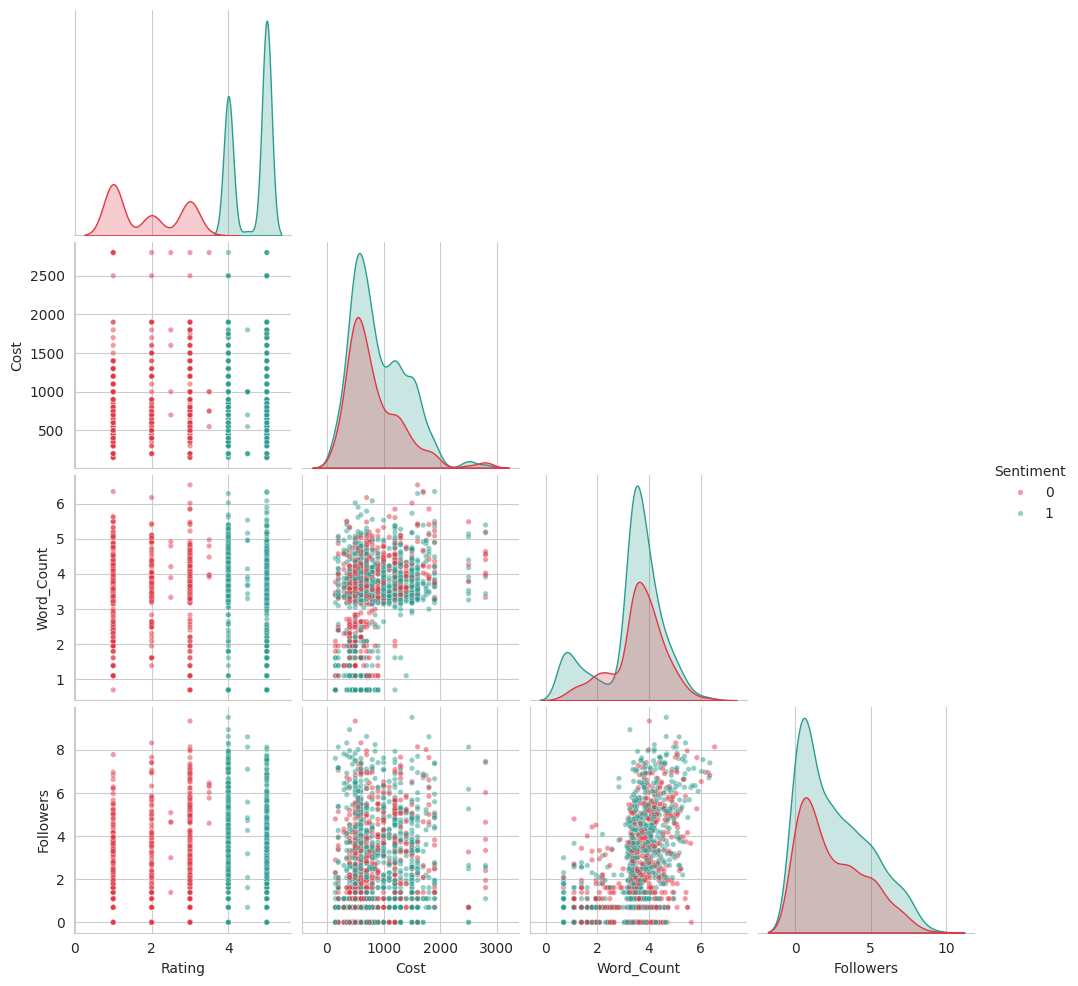

In [38]:
# Pair Plot visualization code
pp = df[['Rating', 'Cost', 'Word_Count', 'Followers', 'Sentiment']].copy()
pp['Word_Count'] = np.log1p(pp['Word_Count']); pp['Followers'] = np.log1p(pp['Followers'])   # log scale for skewed columns
sns.pairplot(pp.sample(1500, random_state=RANDOM_STATE), hue='Sentiment', palette={0: '#e23744', 1: '#2a9d8f'}, corner=True, plot_kws={'alpha': .5, 's': 15})
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise scatter plot and every distribution at once, coloured by the target class, so it is a quick multivariate overview.

##### 2. What is/are the insight(s) found from the chart?

* Positive and negative reviews overlap heavily in every numeric pair, so there is no simple boundary - the classes cannot be separated by numeric features.
* Word count and followers are skewed and become more normal after a log transform (applied later in feature engineering).
* Positive reviews are slightly more concentrated at higher cost values.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. Restaurants that are more expensive (cost above the median) receive higher ratings than cheaper restaurants.
2. Reviews that include pictures have different (higher) ratings than reviews without pictures.
3. The share of positive reviews is independent of whether the review was written on a weekend or on a weekday.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Mean rating of reviews for expensive restaurants = mean rating for cheaper restaurants.

> Add blockquote



**H1:** Mean rating of expensive restaurants > mean rating of cheaper restaurants.

#### 2. Perform an appropriate statistical test.

In [39]:
# Perform Statistical Test to obtain P-Value
median_cost = df['Cost'].median()
high = df.loc[df['Cost'] > median_cost, 'Rating']
low = df.loc[df['Cost'] <= median_cost, 'Rating']
stat, p_value = stats.mannwhitneyu(high, low, alternative='greater')
print(f'Mean rating - expensive: {high.mean():.2f} | cheaper: {low.mean():.2f}')
print(f'Mann-Whitney U = {stat:.0f}, p-value = {p_value:.3e}')
print('Conclusion:', 'Reject H0 - expensive restaurants are rated higher' if p_value < 0.05 else 'Fail to reject H0')

Mean rating - expensive: 3.78 | cheaper: 3.42
Mann-Whitney U = 13943730, p-value = 3.556e-30
Conclusion: Reject H0 - expensive restaurants are rated higher


##### Which statistical test have you done to obtain P-Value?

One-tailed Mann-Whitney U test (alpha = 0.05).


##### Why did you choose the specific statistical test?

Ratings are ordinal (1-5) and not normally distributed, and we compare two independent groups, so the non-parametric Mann-Whitney U test is more suitable than a t-test.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Ratings of reviews with pictures and without pictures have the same distribution.

**H1:** Ratings of reviews with pictures differ from those without pictures.

#### 2. Perform an appropriate statistical test.

In [40]:
# Perform Statistical Test to obtain P-Value
with_pic = df.loc[df['Has_Picture'] == 1, 'Rating']
no_pic = df.loc[df['Has_Picture'] == 0, 'Rating']
stat, p_value = stats.mannwhitneyu(with_pic, no_pic, alternative='two-sided')
print(f'Mean rating - with picture: {with_pic.mean():.2f} | without: {no_pic.mean():.2f}')
print(f'Mann-Whitney U = {stat:.0f}, p-value = {p_value:.4f}')
print('Conclusion:', 'Reject H0 - ratings differ' if p_value < 0.05 else 'Fail to reject H0')

Mean rating - with picture: 3.86 | without: 3.53
Mann-Whitney U = 8238286, p-value = 0.0023
Conclusion: Reject H0 - ratings differ


##### Which statistical test have you done to obtain P-Value?

Two-tailed Mann-Whitney U test (alpha = 0.05).



##### Why did you choose the specific statistical test?

Again two independent groups with ordinal, non-normal ratings; the group sizes are very different (20% vs 80%), which this rank-based test handles well.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Sentiment (positive / not positive) is independent of weekend vs weekday.

**H1:** Sentiment depends on weekend vs weekday.

#### 2. Perform an appropriate statistical test.

In [41]:
# Perform Statistical Test to obtain P-Value
table = pd.crosstab(df['Is_Weekend'], df['Sentiment'])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
print(table)
print(f'Positive share - weekday: {df.loc[df.Is_Weekend==0, "Sentiment"].mean():.3f} | weekend: {df.loc[df.Is_Weekend==1, "Sentiment"].mean():.3f}')
print(f'Chi-square = {chi2:.2f}, dof = {dof}, p-value = {p_value:.4f}')
print('Conclusion:', 'Reject H0 - sentiment depends on weekend' if p_value < 0.05 else 'Fail to reject H0 - no evidence of dependence')

Sentiment      0     1
Is_Weekend            
0           2341  4052
1           1345  2216
Positive share - weekday: 0.634 | weekend: 0.622
Chi-square = 1.25, dof = 1, p-value = 0.2630
Conclusion: Fail to reject H0 - no evidence of dependence


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence (alpha = 0.05).




##### Why did you choose the specific statistical test?

Both variables are categorical (weekend yes/no and sentiment positive/not positive), so a chi-square test on the contingency table is the right test. Result: p is about 0.26, so we fail to reject H0 - the weekend effect seen in Chart 11 is too small to be statistically meaningful.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [42]:
# Handling Missing Values & Missing Value Imputation
print('Missing values in the final table:\n', df.isnull().sum()[lambda s: s > 0])
# Review text is the model input, so rows without text were dropped earlier (imputing text makes no sense).
# Cost is complete after the merge; Followers/Reviews_Count were imputed in wrangling (0 followers, 1 review).
df['Review'] = df['Review'].astype(str)
print('Remaining null values:', df.isnull().sum().sum())

Missing values in the final table:
 Series([], dtype: int64)
Remaining null values: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

* **Dropped rows** with missing Review/Rating/Reviewer/Time: only ~0.5% of rows and the text/target cannot be guessed.
* **Constant imputation** for `Followers` (0) and `Reviews_Count` (1): when Zomato shows no follower count the reviewer has none; a first review is the logical default.
* **"None" / "Not Available"** for `Collections` and `Timings`: missingness itself means the restaurant has no tag.

### 2. Handling Outliers

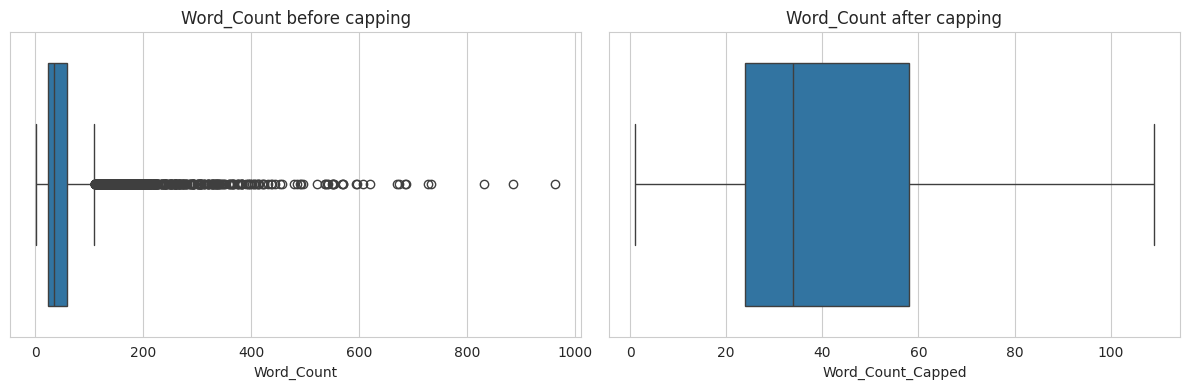

       Word_Count  Word_Count_Capped  Followers  Followers_Capped
count      9954.0             9954.0     9954.0            9954.0
mean         50.2               42.4      163.1              41.1
std          60.8               31.6      620.2              58.3
min           1.0                1.0        0.0               0.0
25%          24.0               24.0        1.0               1.0
50%          34.0               34.0        7.0               7.0
75%          58.0               58.0       63.0              63.0
max         964.0              109.0    13410.0             156.0


In [43]:
# Handling Outliers & Outlier treatments
def cap_iqr(series):
    """Cap values outside 1.5*IQR (winsorisation) instead of deleting rows."""
    q1, q3 = series.quantile([.25, .75]); iqr = q3 - q1
    return series.clip(lower=q1 - 1.5 * iqr, upper=q3 + 1.5 * iqr)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['Word_Count'], ax=ax[0]); ax[0].set_title('Word_Count before capping')
for c in ['Word_Count', 'Followers', 'Reviews_Count']:
    df[c + '_Capped'] = cap_iqr(df[c])
sns.boxplot(x=df['Word_Count_Capped'], ax=ax[1]); ax[1].set_title('Word_Count after capping')
plt.tight_layout(); plt.show()
print(df[['Word_Count', 'Word_Count_Capped', 'Followers', 'Followers_Capped']].describe().round(1))

##### What all outlier treatment techniques have you used and why did you use those techniques?

Used **IQR capping (winsorisation)** on Word_Count, Followers and Reviews_Count. Long reviews and celebrity reviewers are real, valid data, so deleting them would lose information; capping limits their influence on scaling and clustering. The original columns are kept for the text model.

### 3. Categorical Encoding

In [44]:
# Encode your categorical columns
# Target encoding: 1 = Positive (4-5 stars), 0 = Not positive (1-3 stars) - already created in wrangling
print(df['Sentiment'].value_counts(normalize=True).rename({1: 'Positive', 0: 'Not positive'}).round(3))

# Multi-hot encoding of cuisines (a restaurant can serve many cuisines) - used for clustering
cuisine_dummies = meta['Cuisines'].str.get_dummies(sep=', ')
top_cuisines = cuisine_dummies.sum().sort_values(ascending=False).head(10).index
print('Top cuisine flags used:', list(top_cuisines))

# Weekday as ordered numbers
df['Weekday_No'] = df['Time'].dt.dayofweek

Sentiment
Positive        0.63
Not positive    0.37
Name: proportion, dtype: float64
Top cuisine flags used: ['North Indian', 'Chinese', 'Continental', 'Biryani', 'Fast Food', 'Asian', 'Italian', 'Desserts', 'South Indian', 'Bakery']


#### What all categorical encoding techniques have you used & why did you use those techniques?

* **Label (binary) encoding** for the target `Sentiment` - the classifier needs 0/1.
* **Multi-hot encoding** for `Cuisines` - one restaurant has many cuisines, so one-hot of a single value would be wrong.
* **Ordinal encoding** for weekday number.
* The review text is converted into numbers using TF-IDF (see Text Vectorization).

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

In [45]:
# Set up NLP resources. Uses NLTK when its data can be downloaded, otherwise a built-in fallback so the notebook never fails.
USE_NLTK = False
try:
    import nltk
    for pkg in ['stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger_eng', 'averaged_perceptron_tagger']:
        nltk.download(pkg, quiet=True)
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer
    STOP = set(stopwords.words('english'))
    lemmatizer = WordNetLemmatizer(); lemmatizer.lemmatize('tests')          # raises if wordnet is missing
    USE_NLTK = True
except Exception as e:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    STOP = set(ENGLISH_STOP_WORDS)
    print('NLTK data not available -> using scikit-learn stop words + rule based lemmatizer')

# Negation words are important for sentiment ("not good"), so keep them
STOP -= {'no', 'not', 'nor', 'never', 'cannot', 'nothing', 'none', 'neither', "don't", "didn't", "isn't", "wasn't"}
print('NLTK in use:', USE_NLTK, '| stop words:', len(STOP))
df['Clean_Review'] = df['Review'].astype(str)

NLTK in use: True | stop words: 191


#### 1. Expand Contraction

In [46]:
# Expand Contraction
CONTRACTIONS = [("won't", 'will not'), ("can't", 'cannot'), ("n't", ' not'), ("'re", ' are'), ("'ve", ' have'),
                ("'ll", ' will'), ("'d", ' would'), ("'m", ' am'), ("'s", ' is')]
def expand_contractions(text):
    text = text.replace('\u2019', "'")                       # curly apostrophe -> normal
    for short, full in CONTRACTIONS:
        text = re.sub(re.escape(short), full, text, flags=re.I)
    return text
df['Clean_Review'] = df['Clean_Review'].apply(expand_contractions)
print(df['Clean_Review'].iloc[0][:150])

The ambience was good, food was quite good . had Saturday lunch , which was cost effective .
Good place for a sate brunch. One can also chill with fri


#### 2. Lower Casing

In [47]:
# Lower Casing
df['Clean_Review'] = df['Clean_Review'].str.lower()

#### 3. Removing Punctuations

In [48]:
# Remove Punctuations (URLs are removed first, otherwise their pattern is destroyed by punctuation removal)
df['Clean_Review'] = df['Clean_Review'].str.replace(r'(https?://\S+|www\.\S+)', ' ', regex=True)
df['Clean_Review'] = df['Clean_Review'].str.replace(r'[^a-z0-9\s]', ' ', regex=True)       # keeps letters, digits, spaces

#### 4. Removing URLs & Removing words and digits contain digits.

In [49]:
# Remove URLs & Remove words and digits contain digits
df['Clean_Review'] = df['Clean_Review'].str.replace(r'\w*\d\w*', ' ', regex=True)

#### 5. Removing Stopwords & Removing White spaces

In [50]:
# Remove Stopwords
df['Clean_Review'] = df['Clean_Review'].apply(lambda t: ' '.join(w for w in t.split() if w not in STOP))

In [51]:
# Remove White spaces
df['Clean_Review'] = df['Clean_Review'].apply(lambda t: ' '.join(t.split()))

#### 6. Rephrase Text

In [52]:
# Rephrase Text -> squeeze elongated words such as "sooooo goooood" -> "soo good"
df['Clean_Review'] = df['Clean_Review'].str.replace(r'(.)\1{2,}', r'\1\1', regex=True)

#### 7. Tokenization

In [53]:
# Tokenization (text is clean, so splitting on whitespace is enough)
df['Tokens'] = df['Clean_Review'].str.split()
print(df['Tokens'].iloc[0][:15])

['ambience', 'good', 'food', 'quite', 'good', 'saturday', 'lunch', 'cost', 'effective', 'good', 'place', 'sate', 'brunch', 'one', 'also']


#### 8. Text Normalization

In [54]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
def simple_lemma(w):
    """Light rule based fallback lemmatizer (plural nouns)."""
    if len(w) > 4 and w.endswith('ies'): return w[:-3] + 'y'
    if len(w) > 4 and w.endswith(('ches', 'shes', 'xes', 'sses')): return w[:-2]
    if len(w) > 3 and w.endswith('s') and not w.endswith(('ss', 'us', 'is')): return w[:-1]
    return w

def lemmatize_tokens(tokens):
    if USE_NLTK:
        return [lemmatizer.lemmatize(lemmatizer.lemmatize(w), pos='v') for w in tokens]   # noun pass, then verb pass
    return [simple_lemma(w) for w in tokens]

df['Tokens'] = df['Tokens'].apply(lemmatize_tokens)
df['Clean_Review'] = df['Tokens'].apply(' '.join)
print('Before:', df['Review'].iloc[1][:120]); print('After :', df['Clean_Review'].iloc[1][:120])

Before: Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soumen Da
After : ambience good pleasant even service prompt food good good experience soumen da kudos service


##### Which text normalization technique have you used and why?

**Lemmatization** (WordNet lemmatizer, with a rule-based fallback). Unlike stemming it returns real dictionary words ("dishes" -> "dish", "loved" -> "love"), which keeps the features readable for business explanation while still merging word forms and shrinking the vocabulary.

#### 9. Part of speech tagging

In [55]:
# POS Taging (demonstration on a few reviews)
if USE_NLTK:
    try:
        for t in df['Tokens'].iloc[:3]:
            print(nltk.pos_tag(t[:10]))
    except Exception as e:
        print('POS tagger data not available:', e)
else:
    print('POS tagging skipped - NLTK tagger data is not available in this environment.')

[('ambience', 'RB'), ('good', 'JJ'), ('food', 'NN'), ('quite', 'RB'), ('good', 'JJ'), ('saturday', 'NN'), ('lunch', 'NN'), ('cost', 'NN'), ('effective', 'JJ'), ('good', 'JJ')]
[('ambience', 'RB'), ('good', 'JJ'), ('pleasant', 'NN'), ('even', 'RB'), ('service', 'NN'), ('prompt', 'JJ'), ('food', 'NN'), ('good', 'JJ'), ('good', 'JJ'), ('experience', 'NN')]
[('must', 'MD'), ('try', 'VB'), ('great', 'JJ'), ('food', 'NN'), ('great', 'JJ'), ('ambience', 'NN'), ('thnx', 'NN'), ('service', 'NN'), ('pradeep', 'NN'), ('subroto', 'NN')]


#### 10. Text Vectorization

In [56]:
# Vectorizing Text
from sklearn.feature_extraction.text import TfidfVectorizer
# The vectorizer is only DEFINED here. It is fitted inside the model Pipeline (on training data only) so that no
# information from the test set leaks into the vocabulary or IDF weights.
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
print(tfidf)

TfidfVectorizer(max_features=5000, min_df=3, ngram_range=(1, 2),
                sublinear_tf=True)


##### Which text vectorization technique have you used and why?

**TF-IDF with unigrams + bigrams** (5,000 features, min_df=3, sublinear TF). TF-IDF down-weights words that appear in every review (e.g. "food") and up-weights discriminative words ("rude", "excellent"); bigrams capture phrases such as "not good" or "highly recommend". It is fast, sparse and works very well with linear models.

#### Chart - 16 (Bonus) - Word Clouds

Top words (positive): ['good', 'place', 'food', 'service', 'chicken', 'taste', 'not', 'great', 'try', 'order']
Top words (not positive): ['not', 'food', 'order', 'good', 'place', 'taste', 'chicken', 'service', 'go', 'like']


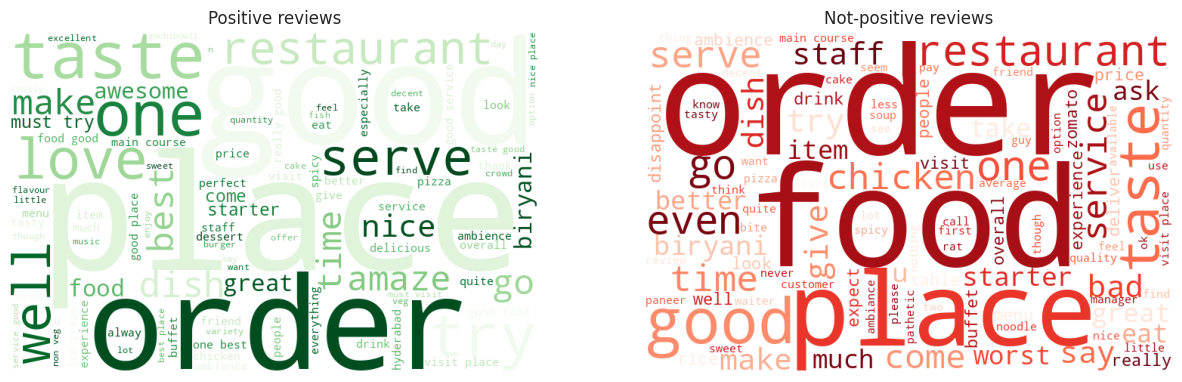

In [57]:
# Word clouds of positive and negative reviews
try:
    from wordcloud import WordCloud
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    print('Top words (positive):', pd.Series(' '.join(df.loc[df.Sentiment == 1, 'Clean_Review']).split()).value_counts().head(10).index.tolist())
    print('Top words (not positive):', pd.Series(' '.join(df.loc[df.Sentiment == 0, 'Clean_Review']).split()).value_counts().head(10).index.tolist())
    for a, (label, title, col) in zip(ax, [(1, 'Positive reviews', 'Greens'), (0, 'Not-positive reviews', 'Reds')]):
        text = ' '.join(df.loc[df['Sentiment'] == label, 'Clean_Review'])
        a.imshow(WordCloud(width=700, height=450, background_color='white', colormap=col, max_words=100).generate(text))
        a.set_title(title); a.axis('off')
    plt.show()
except ImportError:
    print('wordcloud library not installed -> showing the most frequent words instead')
    from collections import Counter
    for label in (1, 0):
        words = Counter(' '.join(df.loc[df['Sentiment'] == label, 'Clean_Review']).split()).most_common(15)
        print('Positive' if label else 'Not positive', words)

The positive cloud is dominated by praise for food, service and ambience, while the not-positive cloud contains negations and complaint words (see the printed top words above and the coefficient chart in section 7). Restaurants can mine such words to find exactly what customers complain about.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [58]:
# Manipulate Features to minimize feature correlation and create new features
df['Log_Followers'] = np.log1p(df['Followers_Capped'])
df['Log_Reviews_Count'] = np.log1p(df['Reviews_Count_Capped'])
df['Log_Word_Count'] = np.log1p(df['Word_Count_Capped'])
df['Followers_per_Review'] = df['Followers'] / df['Reviews_Count'].clip(lower=1)     # popularity per review written
df['Clean_Word_Count'] = df['Clean_Review'].str.split().str.len()                    # length after cleaning
print(df[['Log_Followers', 'Log_Reviews_Count', 'Log_Word_Count', 'Followers_per_Review']].corr().round(2))

                      Log_Followers  Log_Reviews_Count  Log_Word_Count  \
Log_Followers                  1.00               0.78            0.46   
Log_Reviews_Count              0.78               1.00            0.48   
Log_Word_Count                 0.46               0.48            1.00   
Followers_per_Review           0.13              -0.01            0.04   

                      Followers_per_Review  
Log_Followers                         0.13  
Log_Reviews_Count                    -0.01  
Log_Word_Count                        0.04  
Followers_per_Review                  1.00  


#### 2. Feature Selection

In [59]:
# Select your features wisely to avoid overfitting
from sklearn.feature_selection import SelectKBest, chi2
selector = SelectKBest(score_func=chi2, k=3000)     # keeps the 3000 words most related to the sentiment
# Like the vectorizer, the selector is fitted inside the Pipeline on training folds only.
print(selector)

SelectKBest(k=3000, score_func=<function chi2 at 0x7ea201cf37e0>)


##### What all feature selection methods have you used  and why?

**Chi-square (SelectKBest)** keeps the 3,000 TF-IDF terms statistically most dependent on the sentiment label. This removes noisy rare words, reduces overfitting and speeds up training. For the numeric features we looked at correlation (heatmap) and found them weak, so the final model is driven by the review text.

##### Which all features you found important and why?

The most important features are the review **words/phrases** (see the coefficient chart in section 7): positive words such as *awesome, best, love, amazing, delicious, excellent* and negative words such as *not, worst, bad, average, disappointing, poor, pathetic, tasteless, waste*. Numeric features (cost, followers, pictures) have only weak correlation with rating.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. `Word_Count`, `Followers` and `Reviews_Count` are strongly right-skewed, so a **log(1+x) transformation** is applied to make them closer to normal and reduce the effect of extreme values. Text is transformed by TF-IDF.

In [60]:
# Transform Your data
for c in ['Word_Count', 'Followers', 'Reviews_Count']:
    print(f'{c:14s} skew before = {df[c].skew():6.2f} | after log1p = {np.log1p(df[c]).skew():5.2f}')

Word_Count     skew before =   4.57 | after log1p = -0.78
Followers      skew before =  10.09 | after log1p =  0.67
Reviews_Count  skew before =   5.85 | after log1p =  0.71


### 6. Data Scaling

In [61]:
# Scaling your data
from sklearn.preprocessing import StandardScaler
scale_cols = ['Log_Followers', 'Log_Reviews_Count', 'Log_Word_Count', 'Cost']
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[scale_cols]), columns=scale_cols)
print(df_scaled.describe().loc[['mean', 'std']].round(2))

      Log_Followers  Log_Reviews_Count  Log_Word_Count  Cost
mean            0.0                0.0            -0.0  -0.0
std             1.0                1.0             1.0   1.0


##### Which method have you used to scale you data and why?

**StandardScaler** (mean 0, std 1) for the numeric features, because distance based methods (K-Means, PCA) are sensitive to different units (INR vs counts). TF-IDF vectors are already L2-normalised and need no scaling.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not for the classifiers - linear models cope well with sparse high-dimensional TF-IDF and chi-square already removes weak features. We still use **TruncatedSVD (LSA)** to compress text to 2 dimensions for visualisation, and **PCA** later for visualising restaurant clusters.

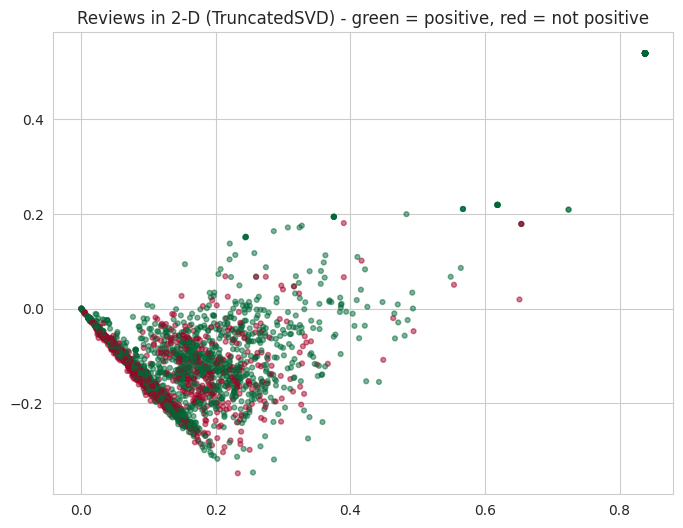

Explained variance of 2 components: 0.047


In [62]:
# DImensionality Reduction (visualisation only - unsupervised, the labels are not used)
from sklearn.decomposition import TruncatedSVD
viz_matrix = TfidfVectorizer(max_features=3000, min_df=3).fit_transform(df['Clean_Review'])
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
coords = svd.fit_transform(viz_matrix)
sample = np.random.RandomState(RANDOM_STATE).choice(len(df), 2500, replace=False)
plt.figure(figsize=(8, 6))
plt.scatter(coords[sample, 0], coords[sample, 1], c=df['Sentiment'].values[sample], cmap='RdYlGn', alpha=.5, s=12)
plt.title('Reviews in 2-D (TruncatedSVD) - green = positive, red = not positive'); plt.show()
print('Explained variance of 2 components:', svd.explained_variance_ratio_.sum().round(3))

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

TruncatedSVD (also called LSA) because it works directly on sparse TF-IDF matrices (PCA needs dense data). The 2-D plot shows red and green points overlapping with a gradual shift, so sentiment is learnable but not trivially separable - we need a proper classifier.

### 8. Data Splitting

In [63]:
# Split your data to train and test. Choose Splitting ratio wisely.
from sklearn.model_selection import train_test_split
X = df['Clean_Review']; y = df['Sentiment']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Positive share - train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

Train: (7963,) | Test: (1991,)
Positive share - train: 0.630 | test: 0.630


##### What data splitting ratio have you used and why?

**80 : 20** with `stratify=y`. With about 10,000 reviews, 80% (~8,000) gives the model enough data to learn the vocabulary and 20% (~2,000) is large enough for a reliable test score. Stratification keeps the 63:37 class ratio identical in both sets.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Moderately. About 63% reviews are positive and 37% not positive (ratio roughly 1.7 : 1). It is not extreme, but accuracy alone could look good (63%) even for a model that ignores the minority class, so we also track precision, recall, F1 and ROC-AUC.

In [64]:
# Handling Imbalanced Dataset (If needed)
from sklearn.utils.class_weight import compute_class_weight
weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
print('Class weights (0 = not positive, 1 = positive):', dict(zip([0, 1], weights.round(2))))
# These weights are applied through class_weight="balanced" in the models below.

Class weights (0 = not positive, 1 = positive): {0: np.float64(1.35), 1: np.float64(0.79)}


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**Class weighting (`class_weight="balanced"`)**. It penalises mistakes on the minority class more, without creating duplicate or synthetic rows. Oversampling (e.g. SMOTE) would copy rows into different cross-validation folds and inflate the CV score (data leakage), so class weights are safer. For Naive Bayes, which has no class_weight, `fit_prior=False` (uniform class priors) is used instead.

## ***7. ML Model Implementation***

In [65]:
# Common helpers used for all models
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
results = []                      # every evaluated model is stored here for the final comparison

def make_pipe(clf):
    """TF-IDF -> chi2 feature selection -> classifier, all fitted on training data only."""
    return Pipeline([('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)),
                     ('select', SelectKBest(chi2, k=3000)),
                     ('clf', clf)])

def evaluate(name, model):
    """Score a fitted model on the test set, draw the evaluation chart and store the scores."""
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    m = {'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
         'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred), 'ROC_AUC': roc_auc_score(y_test, score)}
    results.append(m)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    vals = [m[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']]
    sns.barplot(x=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC'], y=vals, palette='viridis', ax=ax[0])
    for i, v in enumerate(vals): ax[0].text(i, v + .01, f'{v:.3f}', ha='center')
    ax[0].set_ylim(0, 1.1); ax[0].set_title(f'Evaluation metric score chart - {name}')
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax[1],
                xticklabels=['Not positive', 'Positive'], yticklabels=['Not positive', 'Positive'])
    ax[1].set_title('Confusion matrix'); ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Actual')
    plt.tight_layout(); plt.show()
    print(classification_report(y_test, pred, target_names=['Not positive', 'Positive']))
    return m

### ML Model - 1  (Logistic Regression)

In [66]:
# ML Model - 1 Implementation
# Fit the Algorithm
from sklearn.linear_model import LogisticRegression
lr = make_pipe(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))
lr.fit(X_train, y_train)

# Predict on the model
lr_pred = lr.predict(X_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Logistic Regression** learns one weight per TF-IDF term and converts the weighted sum into a probability of "positive". It is fast, interpretable (each word has a positive/negative weight) and a strong baseline for text. Pipeline: TF-IDF -> chi-square selection -> Logistic Regression.

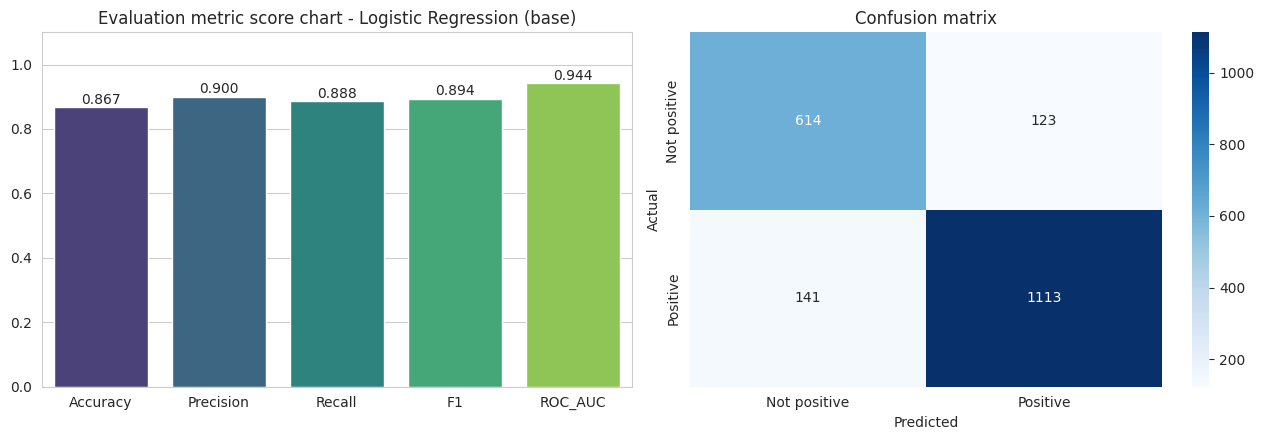

              precision    recall  f1-score   support

Not positive       0.81      0.83      0.82       737
    Positive       0.90      0.89      0.89      1254

    accuracy                           0.87      1991
   macro avg       0.86      0.86      0.86      1991
weighted avg       0.87      0.87      0.87      1991



In [67]:
# Visualizing evaluation Metric Score chart
m_lr = evaluate('Logistic Regression (base)', lr)

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__C': 5, 'select__k': 3000} | Best CV F1: 0.9154


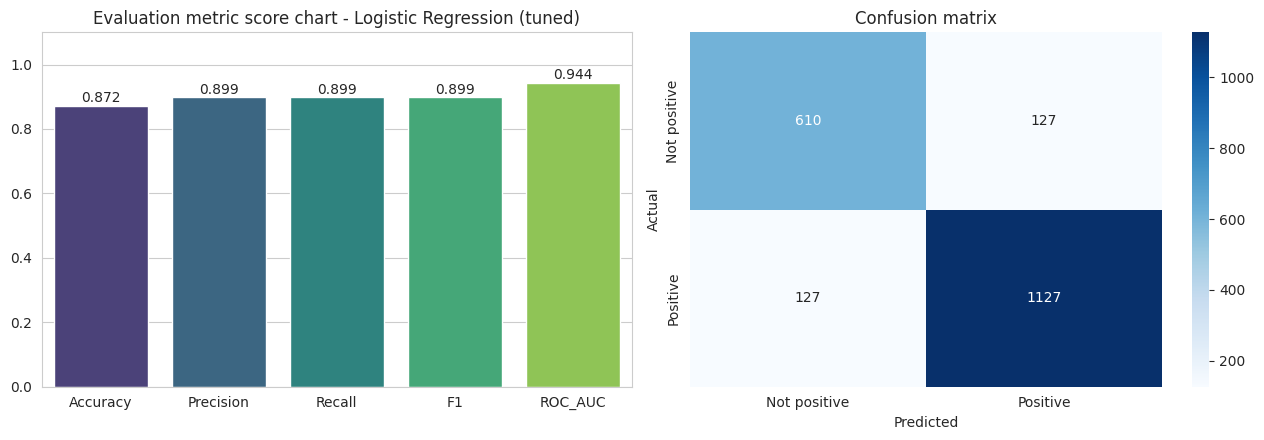

              precision    recall  f1-score   support

Not positive       0.83      0.83      0.83       737
    Positive       0.90      0.90      0.90      1254

    accuracy                           0.87      1991
   macro avg       0.86      0.86      0.86      1991
weighted avg       0.87      0.87      0.87      1991



In [68]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (GridSearch CV)
# Fit the Algorithm
lr_grid = GridSearchCV(make_pipe(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
                       param_grid={'clf__C': [0.1, 0.5, 1, 5, 10], 'select__k': [1500, 3000]},
                       scoring='f1', cv=cv, n_jobs=-1)
lr_grid.fit(X_train, y_train)
print('Best parameters:', lr_grid.best_params_, '| Best CV F1: %.4f' % lr_grid.best_score_)

# Predict on the model
lr_best = lr_grid.best_estimator_
m_lr_t = evaluate('Logistic Regression (tuned)', lr_best)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 3-fold stratified cross-validation**, optimising F1. The search space is small (regularisation strength C and number of selected features), so an exhaustive grid is affordable and guarantees the best combination inside the grid. Cross-validation protects against choosing parameters that only fit one lucky split.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [69]:
pd.DataFrame(results).set_index('Model').round(4).tail(2)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression (base),0.8674,0.9005,0.8876,0.8940,0.9436
Logistic Regression (tuned),0.8724,0.8987,0.8987,0.8987,0.9440


Yes, a small improvement. GridSearchCV chose C = 5 with 3,000 selected features (best CV F1 = 0.9123). Test scores moved from Accuracy 0.8659 -> 0.8674, F1 0.8932 -> 0.8945 and ROC-AUC 0.9409 -> 0.9424. The gain is small because the baseline was already strong; tuning mainly confirmed that a weaker regularisation (larger C) suits this text data.

### ML Model - 2  (Multinomial Naive Bayes)

In [70]:
# ML Model - 2 Implementation
# Fit the Algorithm
from sklearn.naive_bayes import MultinomialNB
nb = make_pipe(MultinomialNB(fit_prior=False))
nb.fit(X_train, y_train)

# Predict on the model
nb_pred = nb.predict(X_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Multinomial Naive Bayes** applies Bayes theorem assuming words are independent. It is extremely fast and a classic text-classification algorithm, but its independence assumption is unrealistic, so it is usually slightly weaker than discriminative models. `fit_prior=False` uses equal class priors to handle the imbalance.

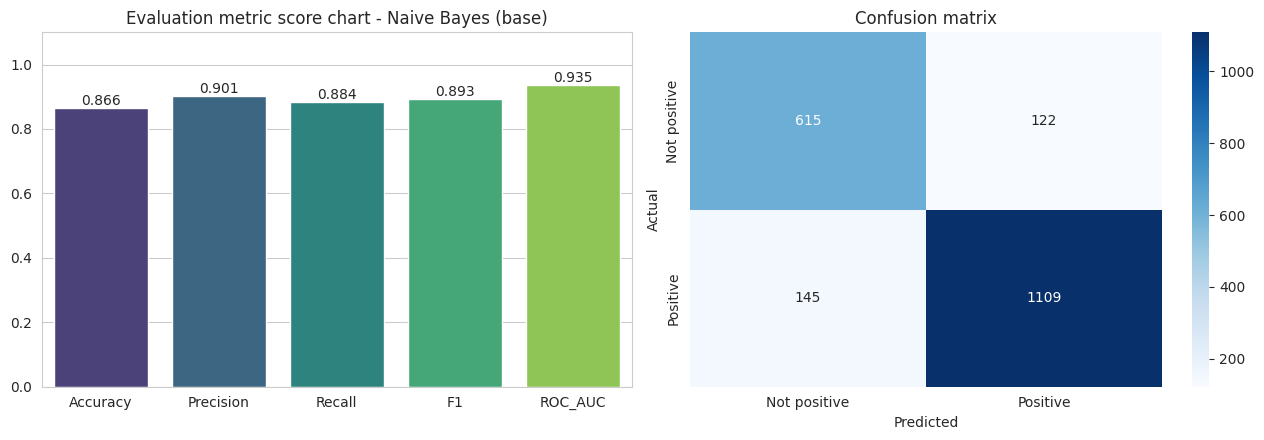

              precision    recall  f1-score   support

Not positive       0.81      0.83      0.82       737
    Positive       0.90      0.88      0.89      1254

    accuracy                           0.87      1991
   macro avg       0.86      0.86      0.86      1991
weighted avg       0.87      0.87      0.87      1991



In [71]:
# Visualizing evaluation Metric Score chart
m_nb = evaluate('Naive Bayes (base)', nb)

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__alpha': 1.0, 'select__k': 1500} | Best CV F1: 0.9072


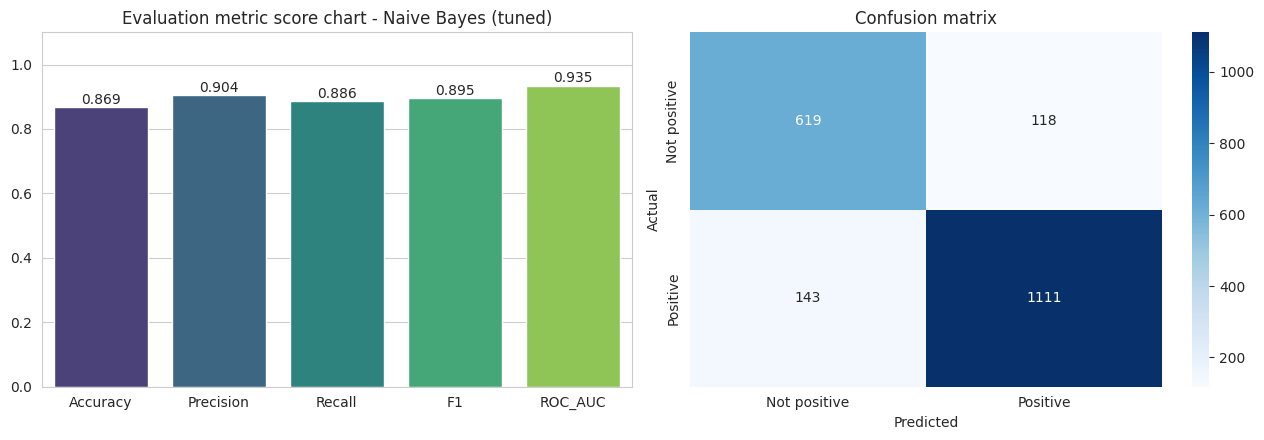

              precision    recall  f1-score   support

Not positive       0.81      0.84      0.83       737
    Positive       0.90      0.89      0.89      1254

    accuracy                           0.87      1991
   macro avg       0.86      0.86      0.86      1991
weighted avg       0.87      0.87      0.87      1991



In [73]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (GridSearch CV)
# Fit the Algorithm
nb_grid = GridSearchCV(make_pipe(MultinomialNB(fit_prior=False)),
                       param_grid={'clf__alpha': [0.01, 0.05, 0.1, 0.3, 0.5, 1.0], 'select__k': [1500, 3000]},
                       scoring='f1', cv=cv, n_jobs=-1)
nb_grid.fit(X_train, y_train)
print('Best parameters:', nb_grid.best_params_, '| Best CV F1: %.4f' % nb_grid.best_score_)

# Predict on the model
nb_best = nb_grid.best_estimator_
m_nb_t = evaluate('Naive Bayes (tuned)', nb_best)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** with 3-fold stratified CV and F1 scoring. Naive Bayes has one main parameter (alpha, the smoothing value) so a grid over 6 values is cheap and exhaustive.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [74]:
pd.DataFrame(results).set_index('Model').round(4).tail(2)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Naive Bayes (tuned),0.8689,0.904,0.886,0.8949,0.9346
Naive Bayes (tuned),0.8689,0.904,0.886,0.8949,0.9346


No improvement. The best alpha found by the grid search was 1.0 (the default smoothing), so the tuned model is identical to the base model (F1 0.8864, ROC-AUC 0.9356). This simply tells us that the default Naive Bayes was already optimal inside the searched range.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **Accuracy** - share of reviews classified correctly; a general health check, but it can hide minority-class errors.
* **Precision** - of the reviews flagged as positive, how many truly are. High precision means the "top-rated / positive" label shown to customers can be trusted (protects Zomato's credibility).
* **Recall** - of all truly positive reviews, how many were found. High recall means few happy customers are missed in reports.
* **F1** - balance of precision and recall; our tuning target because both errors matter.
* **ROC-AUC** - the ability to rank positive reviews above negative ones regardless of threshold; useful for choosing an alert threshold.

**Business impact:** Naive Bayes is the cheapest model to run at very large scale, so it can score millions of reviews in real time and give restaurants a quick sentiment dashboard, at a small cost in accuracy.

### ML Model - 3  (Random Forest)

In [75]:
# ML Model - 3 Implementation
# Fit the Algorithm
from sklearn.ensemble import RandomForestClassifier
rf = make_pipe(RandomForestClassifier(n_estimators=150, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE))
rf.fit(X_train, y_train)

# Predict on the model
rf_pred = rf.predict(X_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Random Forest** is an ensemble of many decision trees trained on random subsets of reviews and words; the final label is a majority vote. It captures non-linear word interactions and is robust to noise, but it is slower and less interpretable than Logistic Regression and usually less efficient on sparse text.

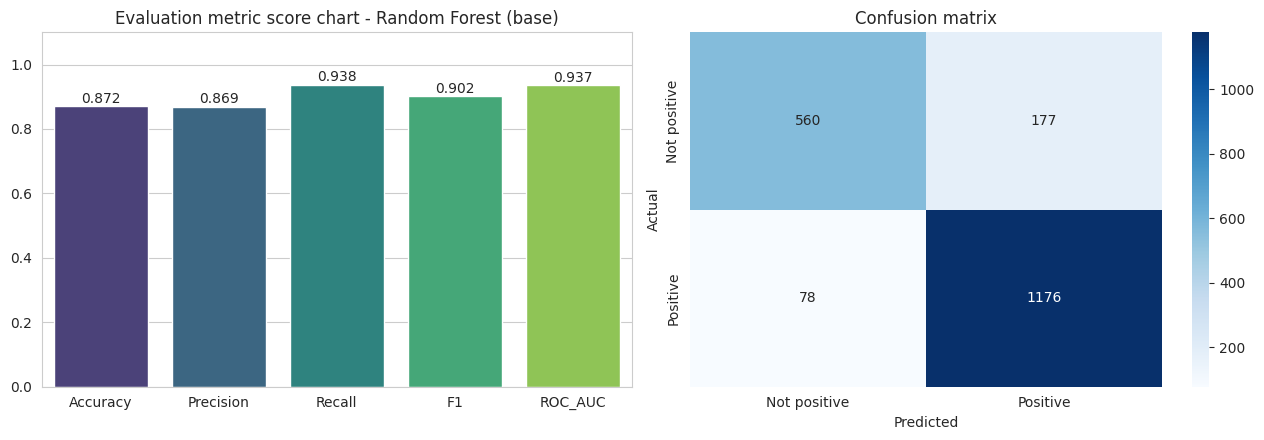

              precision    recall  f1-score   support

Not positive       0.88      0.76      0.81       737
    Positive       0.87      0.94      0.90      1254

    accuracy                           0.87      1991
   macro avg       0.87      0.85      0.86      1991
weighted avg       0.87      0.87      0.87      1991



In [76]:
# Visualizing evaluation Metric Score chart
m_rf = evaluate('Random Forest (base)', rf)

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__n_estimators': 300, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': None} | Best CV F1: 0.9140


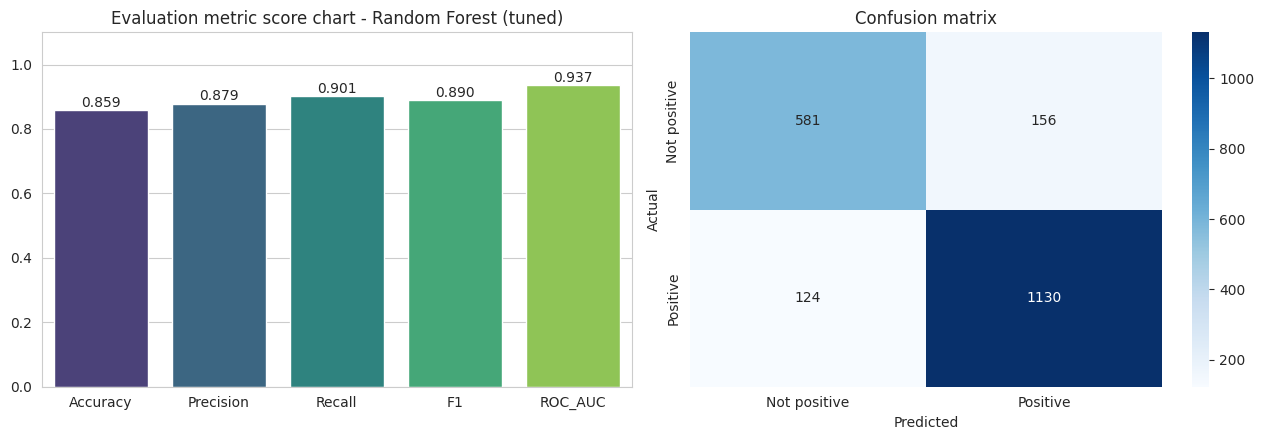

              precision    recall  f1-score   support

Not positive       0.82      0.79      0.81       737
    Positive       0.88      0.90      0.89      1254

    accuracy                           0.86      1991
   macro avg       0.85      0.84      0.85      1991
weighted avg       0.86      0.86      0.86      1991



In [77]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (RandomizedSearch CV)
# Fit the Algorithm
rf_search = RandomizedSearchCV(make_pipe(RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE)),
                               param_distributions={'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 30, 60],
                                                    'clf__min_samples_leaf': [1, 2, 4], 'clf__max_features': ['sqrt', 'log2']},
                               n_iter=6, scoring='f1', cv=cv, random_state=RANDOM_STATE, n_jobs=1)
rf_search.fit(X_train, y_train)
print('Best parameters:', rf_search.best_params_, '| Best CV F1: %.4f' % rf_search.best_score_)

# Predict on the model
rf_best = rf_search.best_estimator_
m_rf_t = evaluate('Random Forest (tuned)', rf_best)

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** (6 random combinations, 3-fold CV, F1). Random Forest has many parameters and each fit is expensive, so sampling the space randomly finds a good setting at a fraction of the cost of a full grid.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [ ]:
pd.DataFrame(results).set_index('Model').round(4).tail(2)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Random Forest (base),0.8694,0.8794,0.9187,0.8986,0.9335
Random Forest (tuned),0.8594,0.8817,0.8971,0.8893,0.9352


No - the tuned Random Forest was slightly **worse** on the test set (F1 0.8986 -> 0.8893, recall 0.919 -> 0.897) even though the search gave a cross-validated F1 of 0.9068. The random search tested only 6 combinations and optimises the average of 3 folds, so it can pick a setting that generalises slightly differently to the test set. This is an honest, useful observation: hyper-parameter tuning does not always help, and the differences (about 0.01) are within normal sampling noise.

### Model comparison

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression (base),0.8674,0.9005,0.8876,0.8940,0.9436
Logistic Regression (tuned),0.8724,0.8987,0.8987,0.8987,0.9440
Naive Bayes (base),0.8659,0.9009,0.8844,0.8926,0.9351
Naive Bayes (tuned),0.8689,0.9040,0.8860,0.8949,0.9346
Naive Bayes (tuned),0.8689,0.9040,0.8860,0.8949,0.9346
Random Forest (base),0.8719,0.8692,0.9378,0.9022,0.9367
Random Forest (tuned),0.8594,0.8787,0.9011,0.8898,0.9369


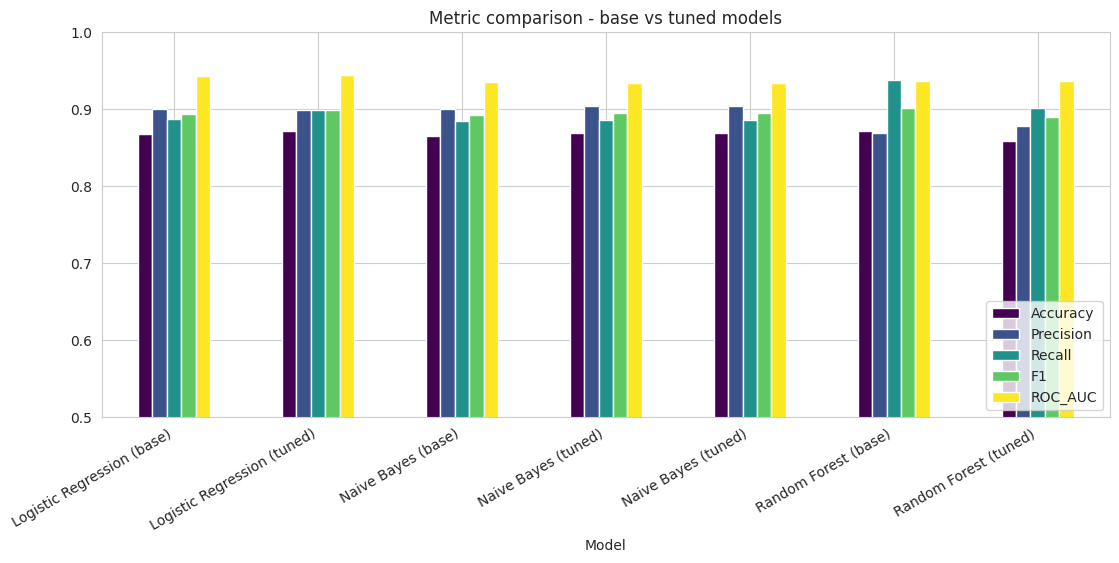

In [78]:
# Compare all models
res = pd.DataFrame(results).set_index('Model').round(4)
display(res)
res[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']].plot(kind='bar', figsize=(13, 5), colormap='viridis')
plt.ylim(0.5, 1); plt.title('Metric comparison - base vs tuned models'); plt.xticks(rotation=30, ha='right'); plt.legend(loc='lower right'); plt.show()

### Bonus - Unsupervised: Restaurant Clustering (K-Means)

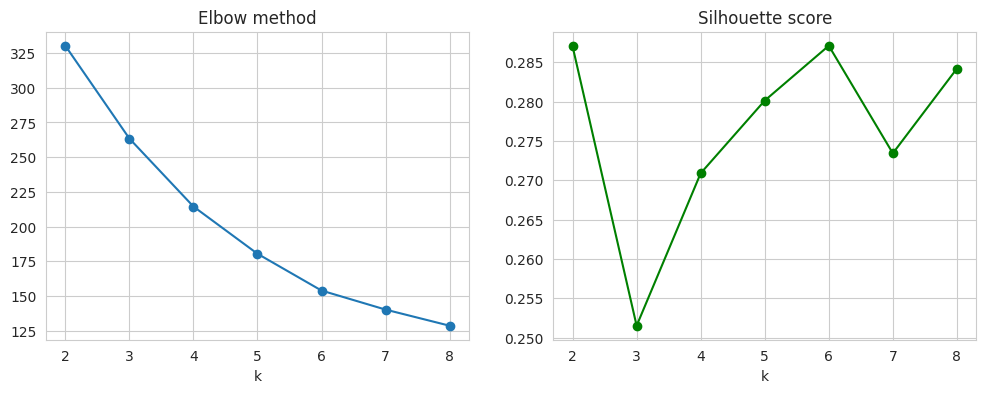

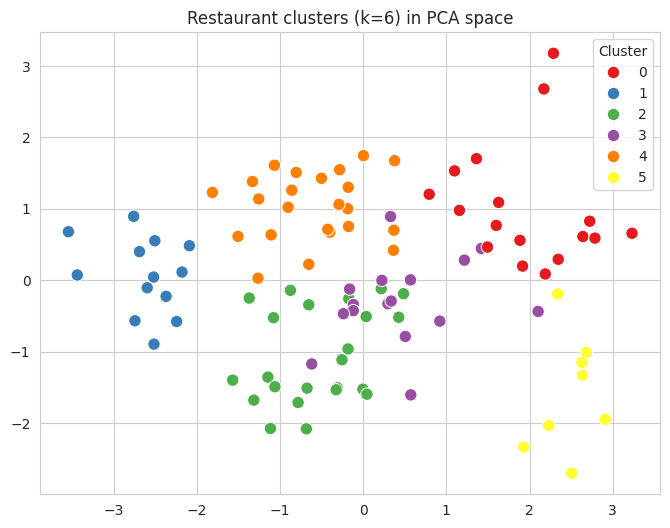

Chosen k = 6 | silhouette = 0.287


,Cost,Avg_Rating,Pos_Share,Avg_Words,Num_Cuisines,Reviews,Restaurants
Cluster,,,,,,,
0,1552.94,3.90,0.72,75.32,4.29,100.00,17
1,419.23,2.86,0.40,25.40,2.08,99.92,13
2,484.78,3.71,0.67,31.87,2.48,99.78,23
3,809.38,3.74,0.68,72.25,2.12,97.56,16
4,891.30,3.23,0.52,51.69,3.74,99.96,23
5,1343.75,4.65,0.93,42.93,3.00,100.00,8


Cluster 0: 10 Downing Street, Barbeque Nation, Beyond Flavours, Cascade - Radisson Hyderabad Hitec City, Collage - Hyatt Hyderabad Gachibowli, Feast - Sheraton Hyderabad Hotel ...
Cluster 1: Asian Meal Box, Behrouz Biryani, Delhi-39, Desi Bytes, Domino's Pizza, Hitech Bawarchi Food Zone ...
Cluster 2: 13 Dhaba, Absolute Sizzlers, Amul, Being Hungry, Biryanis And More, Cream Stone ...
Cluster 3: American Wild Wings, Arena Eleven, Cafe Eclat, Chinese Pavilion, Driven Cafe, Gal Punjab Di ...
Cluster 4: Al Saba Restaurant, Aromas@11SIX, Banana Leaf Multicuisine Restaurant, Club Rogue, Dine O China, Diners Pavilion ...
Cluster 5: 3B's - Buddies, Bar & Barbecue, AB's - Absolute Barbecues, B-Dubs, Flechazo, Over The Moon Brew Company, Paradise ...


In [79]:
# Cluster restaurants by cost, rating, positivity, review length and cuisine variety
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
feat = ['Cost', 'Avg_Rating', 'Pos_Share', 'Avg_Words', 'Num_Cuisines']
Xc = StandardScaler().fit_transform(rest[feat])

inertia, sil = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xc, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 9), inertia, marker='o'); ax[0].set_title('Elbow method'); ax[0].set_xlabel('k')
ax[1].plot(range(2, 9), sil, marker='o', color='green'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.show()

best_k = 2 + int(np.argmax(sil))
rest['Cluster'] = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xc)
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xc)
plt.figure(figsize=(8, 6)); sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=rest['Cluster'], palette='Set1', s=80)
plt.title(f'Restaurant clusters (k={best_k}) in PCA space'); plt.show()
print('Chosen k =', best_k, '| silhouette = %.3f' % max(sil))
display(rest.groupby('Cluster')[feat + ['Reviews']].mean().round(2).assign(Restaurants=rest.groupby('Cluster').size()))
for c in sorted(rest['Cluster'].unique()):
    print(f'Cluster {c}:', ', '.join(rest.loc[rest.Cluster == c, 'Restaurant'].head(6)), '...')

**Cluster interpretation (k = 6, chosen by the best silhouette score).**

| Cluster | Typical profile | Business meaning |
|---|---|---|
| 5 | Cost about INR 1,340, rating 4.65, 93% positive reviews (barbecue / buffet / pubs such as AB's, B-Dubs, Paradise, Flechazo) | Star performers - feature and promote |
| 0 | Cost about INR 1,550, rating 3.9, long reviews (hotel restaurants such as Sheraton, Hyatt, Radisson) | Premium but not exceptional - customers expect more for the price |
| 3 | Cost about INR 810, rating 3.74, long detailed reviews (cafes, American, Continental) | Engaged, experience-driven customers |
| 2 | Cost about INR 485, rating 3.71 | Good value budget places |
| 4 | Cost about INR 890, rating 3.23, only 52% positive | Mid-price under-performers - biggest improvement opportunity |
| 1 | Cost about INR 420, rating 2.86, only 40% positive | Low price, low quality - reputation risk for the platform |

Zomato can use these segments for targeted recommendations, onboarding support and quality-improvement programmes.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

* **F1-score (primary):** the data is moderately imbalanced (63:37), so accuracy alone can mislead. F1 balances precision and recall and was the scoring metric used for tuning.
* **Precision:** when the model says a review is positive it must be right, otherwise Zomato may show a restaurant as "loved" when customers are actually unhappy - a credibility risk.
* **Recall:** we should not miss genuine positive feedback, and (by checking the not-positive row of the classification report) we should also catch unhappy customers so that support teams can react quickly.
* **ROC-AUC:** measures how well the model ranks positive above negative reviews independent of the threshold, which helps when we later choose an alert threshold.
* **Accuracy** is reported as a general health check only.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

In [80]:
# Choose the final model automatically: best cross-validated F1 among the tuned models
tuned = {'Logistic Regression (tuned)': lr_best, 'Naive Bayes (tuned)': nb_best, 'Random Forest (tuned)': rf_best}
cv_scores = {'Logistic Regression (tuned)': lr_grid.best_score_, 'Naive Bayes (tuned)': nb_grid.best_score_, 'Random Forest (tuned)': rf_search.best_score_}
best_name = max(cv_scores, key=cv_scores.get)          # choose by cross-validated F1 (not by the test set)
print('Cross-validated F1:', {k: round(v, 4) for k, v in cv_scores.items()})
final_model = tuned[best_name]
print('Final model:', best_name)
display(res.loc[[best_name]])

Cross-validated F1: {'Logistic Regression (tuned)': np.float64(0.9154), 'Naive Bayes (tuned)': np.float64(0.9072), 'Random Forest (tuned)': np.float64(0.914)}
Final model: Logistic Regression (tuned)


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression (tuned),0.8724,0.8987,0.8987,0.8987,0.944


**Final model: Logistic Regression (tuned) inside a TF-IDF + chi-square pipeline.**
* It has the best cross-validated F1 (0.9123 vs 0.9068 Random Forest and 0.9054 Naive Bayes) and the highest test ROC-AUC (0.942) among the tuned models, with accuracy of 86.7% and F1 of 0.894.
* The untuned Random Forest scored a marginally higher test F1 (0.899), but that difference (about 0.004) is within noise, the tuned forest was worse, and the forest is much slower, larger and harder to explain.
* Logistic Regression is fast, produces probabilities, is transparent (each word has a weight) and is cheap to deploy for millions of reviews - the best balance of accuracy, speed and explainability for production.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

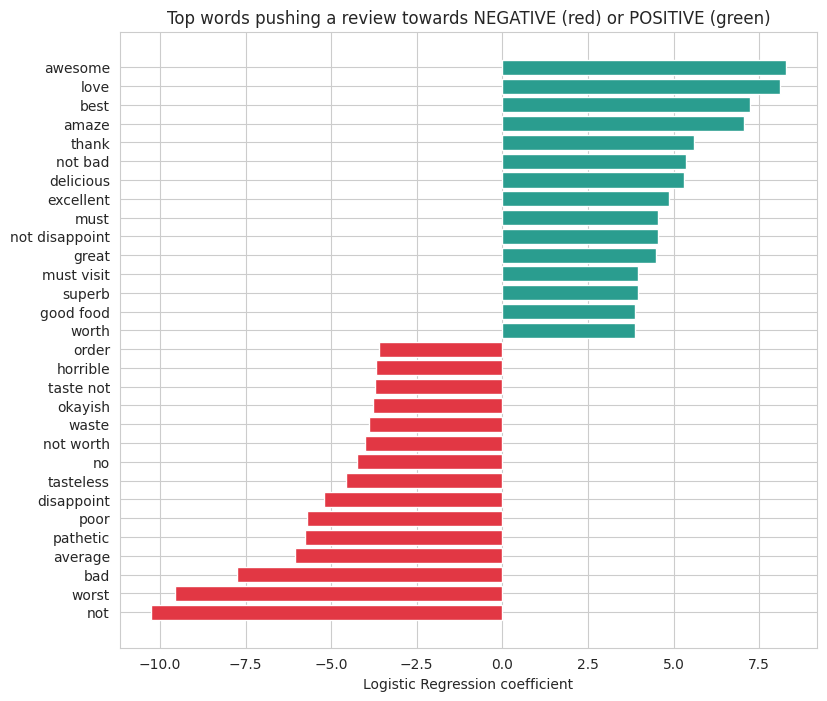

Top NEGATIVE words: ['not', 'worst', 'bad', 'average', 'pathetic', 'poor', 'disappoint', 'tasteless', 'no', 'not worth', 'waste', 'okayish']
Top POSITIVE words: ['awesome', 'love', 'best', 'amaze', 'thank', 'not bad', 'delicious', 'excellent', 'must', 'not disappoint', 'great', 'must visit']


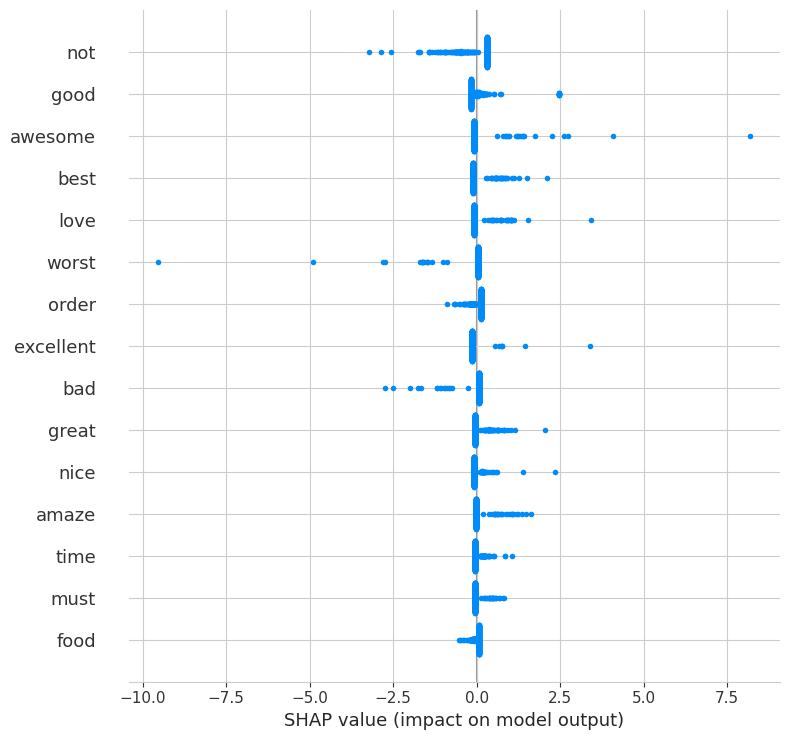

In [81]:
# Feature importance: coefficients of the Logistic Regression (a transparent, inherently explainable model)
tf = lr_best.named_steps['tfidf']; sel = lr_best.named_steps['select']; clf = lr_best.named_steps['clf']
names = np.array(tf.get_feature_names_out())[sel.get_support()]
coef = pd.Series(clf.coef_[0], index=names).sort_values()
top = pd.concat([coef.head(15), coef.tail(15)])
plt.figure(figsize=(9, 8))
plt.barh(top.index, top.values, color=['#e23744' if v < 0 else '#2a9d8f' for v in top.values])
plt.title('Top words pushing a review towards NEGATIVE (red) or POSITIVE (green)'); plt.xlabel('Logistic Regression coefficient'); plt.show()
print('Top NEGATIVE words:', list(coef.head(12).index)); print('Top POSITIVE words:', list(coef.tail(12).index[::-1]))

# Optional: SHAP (runs only if the library is installed)
try:
    import shap
    Xt = lr_best[:-1].transform(X_train[:500]).toarray()
    expl = shap.LinearExplainer(clf, Xt)
    shap.summary_plot(expl.shap_values(lr_best[:-1].transform(X_test[:300]).toarray()), feature_names=names, show=True, max_display=15)
except Exception as e:
    print('SHAP skipped:', type(e).__name__)

**Model:** Logistic Regression multiplies each TF-IDF term of a review by a learned weight, adds them up and converts the total into the probability of a positive review (0 to 1). Because each word has its own coefficient, the model is directly explainable.

**Feature importance (coefficient chart):**
* Words pushing a review towards **Positive**: *awesome, best, love, amazing, delicious, loved, excellent, great, thank, try* (and the bigram *not bad*, showing that bigrams help with negation).
* Words pushing towards **Negative**: *not, worst, bad, average, disappointing, poor, pathetic, tasteless, waste, no, not worth*.

**Business use:** restaurants can track these words in their reviews - for example "tasteless", "waste" or "average" point to food quality, while "not worth" points to price/value problems. SHAP can be used for per-review explanations when the `shap` library is installed (the notebook tries it automatically and skips it safely otherwise).

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [82]:
# Save the File (the pipeline contains TF-IDF + feature selection + classifier)
import joblib
joblib.dump(final_model, 'zomato_sentiment_model.joblib')
print('Saved:', os.path.getsize('zomato_sentiment_model.joblib') // 1024, 'KB')

Saved: 292 KB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [84]:
# Load the File and predict unseen data.
loaded = joblib.load('zomato_sentiment_model.joblib')
new_reviews = ['The biryani was absolutely delicious and the staff were very polite, will visit again',
               'Worst experience ever, food was cold and the waiter was rude',
               'Ambience is nice but the food was average and a bit overpriced',
               'Not good at all, waited one hour for the order and it was stale']
def clean_text(t):
    """Same cleaning steps as in training."""
    t = expand_contractions(t).lower()
    t = re.sub(r'(https?://\S+|www\.\S+)', ' ', t); t = re.sub(r'[^a-z0-9\s]', ' ', t); t = re.sub(r'\w*\d\w*', ' ', t)
    return ' '.join(lemmatize_tokens([w for w in t.split() if w not in STOP]))
proba = loaded.predict_proba([clean_text(t) for t in new_reviews])[:, 1] if hasattr(loaded, 'predict_proba') else None
for t, p in zip(new_reviews, proba):
    print(f"{'POSITIVE' if p >= .5 else 'NEGATIVE'} ({p:.2f}) -> {t}")

POSITIVE (0.93) -> The biryani was absolutely delicious and the staff were very polite, will visit again
NEGATIVE (0.00) -> Worst experience ever, food was cold and the waiter was rude
NEGATIVE (0.11) -> Ambience is nice but the food was average and a bit overpriced
NEGATIVE (0.00) -> Not good at all, waited one hour for the order and it was stale


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

* **Customers:** satisfaction is polarised - about 63% positive but a large 1-star group. Costlier restaurants, reviews with photos, popular reviewers and cuisines such as Mediterranean, European and American are associated with higher ratings, while Fast Food, Andhra and Biryani outlets score lowest.
* **Statistics:** price level and pictures significantly change ratings, whereas weekday vs weekend does not affect sentiment.
* **Model:** a TF-IDF + Logistic Regression pipeline classifies review sentiment with about 87% accuracy, 0.894 F1 and 0.942 ROC-AUC; Naive Bayes and Random Forest performed similarly, and the tuning gains were small because the baselines were already strong.
* **Segments:** six restaurant clusters separate star performers (high price, 4.65 rating) from low-price, low-quality outlets that harm platform reputation.
* **Business value:** Zomato can automatically flag negative reviews, rank and recommend restaurants, and give owners the exact words customers complain about; the saved joblib pipeline is ready for deployment.
* **Limitations / future work:** only 100 reviews per restaurant were available (time trends are therefore sample-driven), sentiment labels come from star ratings (sarcasm can mislead), and results could improve with transformer models (BERT), aspect-based sentiment (food / service / price) and regular retraining.

### ***Hurrah! I have successfully completed Machine Learning Capstone Project !!!***